In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from pathlib import Path

plt.rcParams.update({'figure.dpi': 120, 'font.size': 9})
BASE = Path('ROUND_5')
DAYS = [2, 3, 4]
COLORS5 = ['#e6194b','#3cb44b','#4363d8','#f58231','#911eb4']

frames = []
for d in DAYS:
    df = pd.read_csv(BASE / f'prices_round_5_day_{d}.csv', sep=';') 
    df['day'] = d
    frames.append(df)
prices = pd.concat(frames, ignore_index=True)
prices['global_ts'] = (prices['day'] - DAYS[0]) * 1_000_000 + prices['timestamp']

mid = prices.pivot_table(index='global_ts', columns='product', values='mid_price')
day_starts = [(d - DAYS[0]) * 1_000_000 for d in DAYS]


## 15 — Pebbles: spread decomposition
Six derived series across the basket:
1. **XL − XS** — extreme-size spread
2. **XS+S+M+L+XL** — basket sum (should hug 50 000)
3. **L+S+M** — middle-three sub-basket
4. **Each pebble − 10 000** — deviation from equal fair share
5. **(XL+XS) − (L+S)** — outermost vs second-outermost pair
6. **M − (XS+XL)/2** — middle vs average of extremes (butterfly)


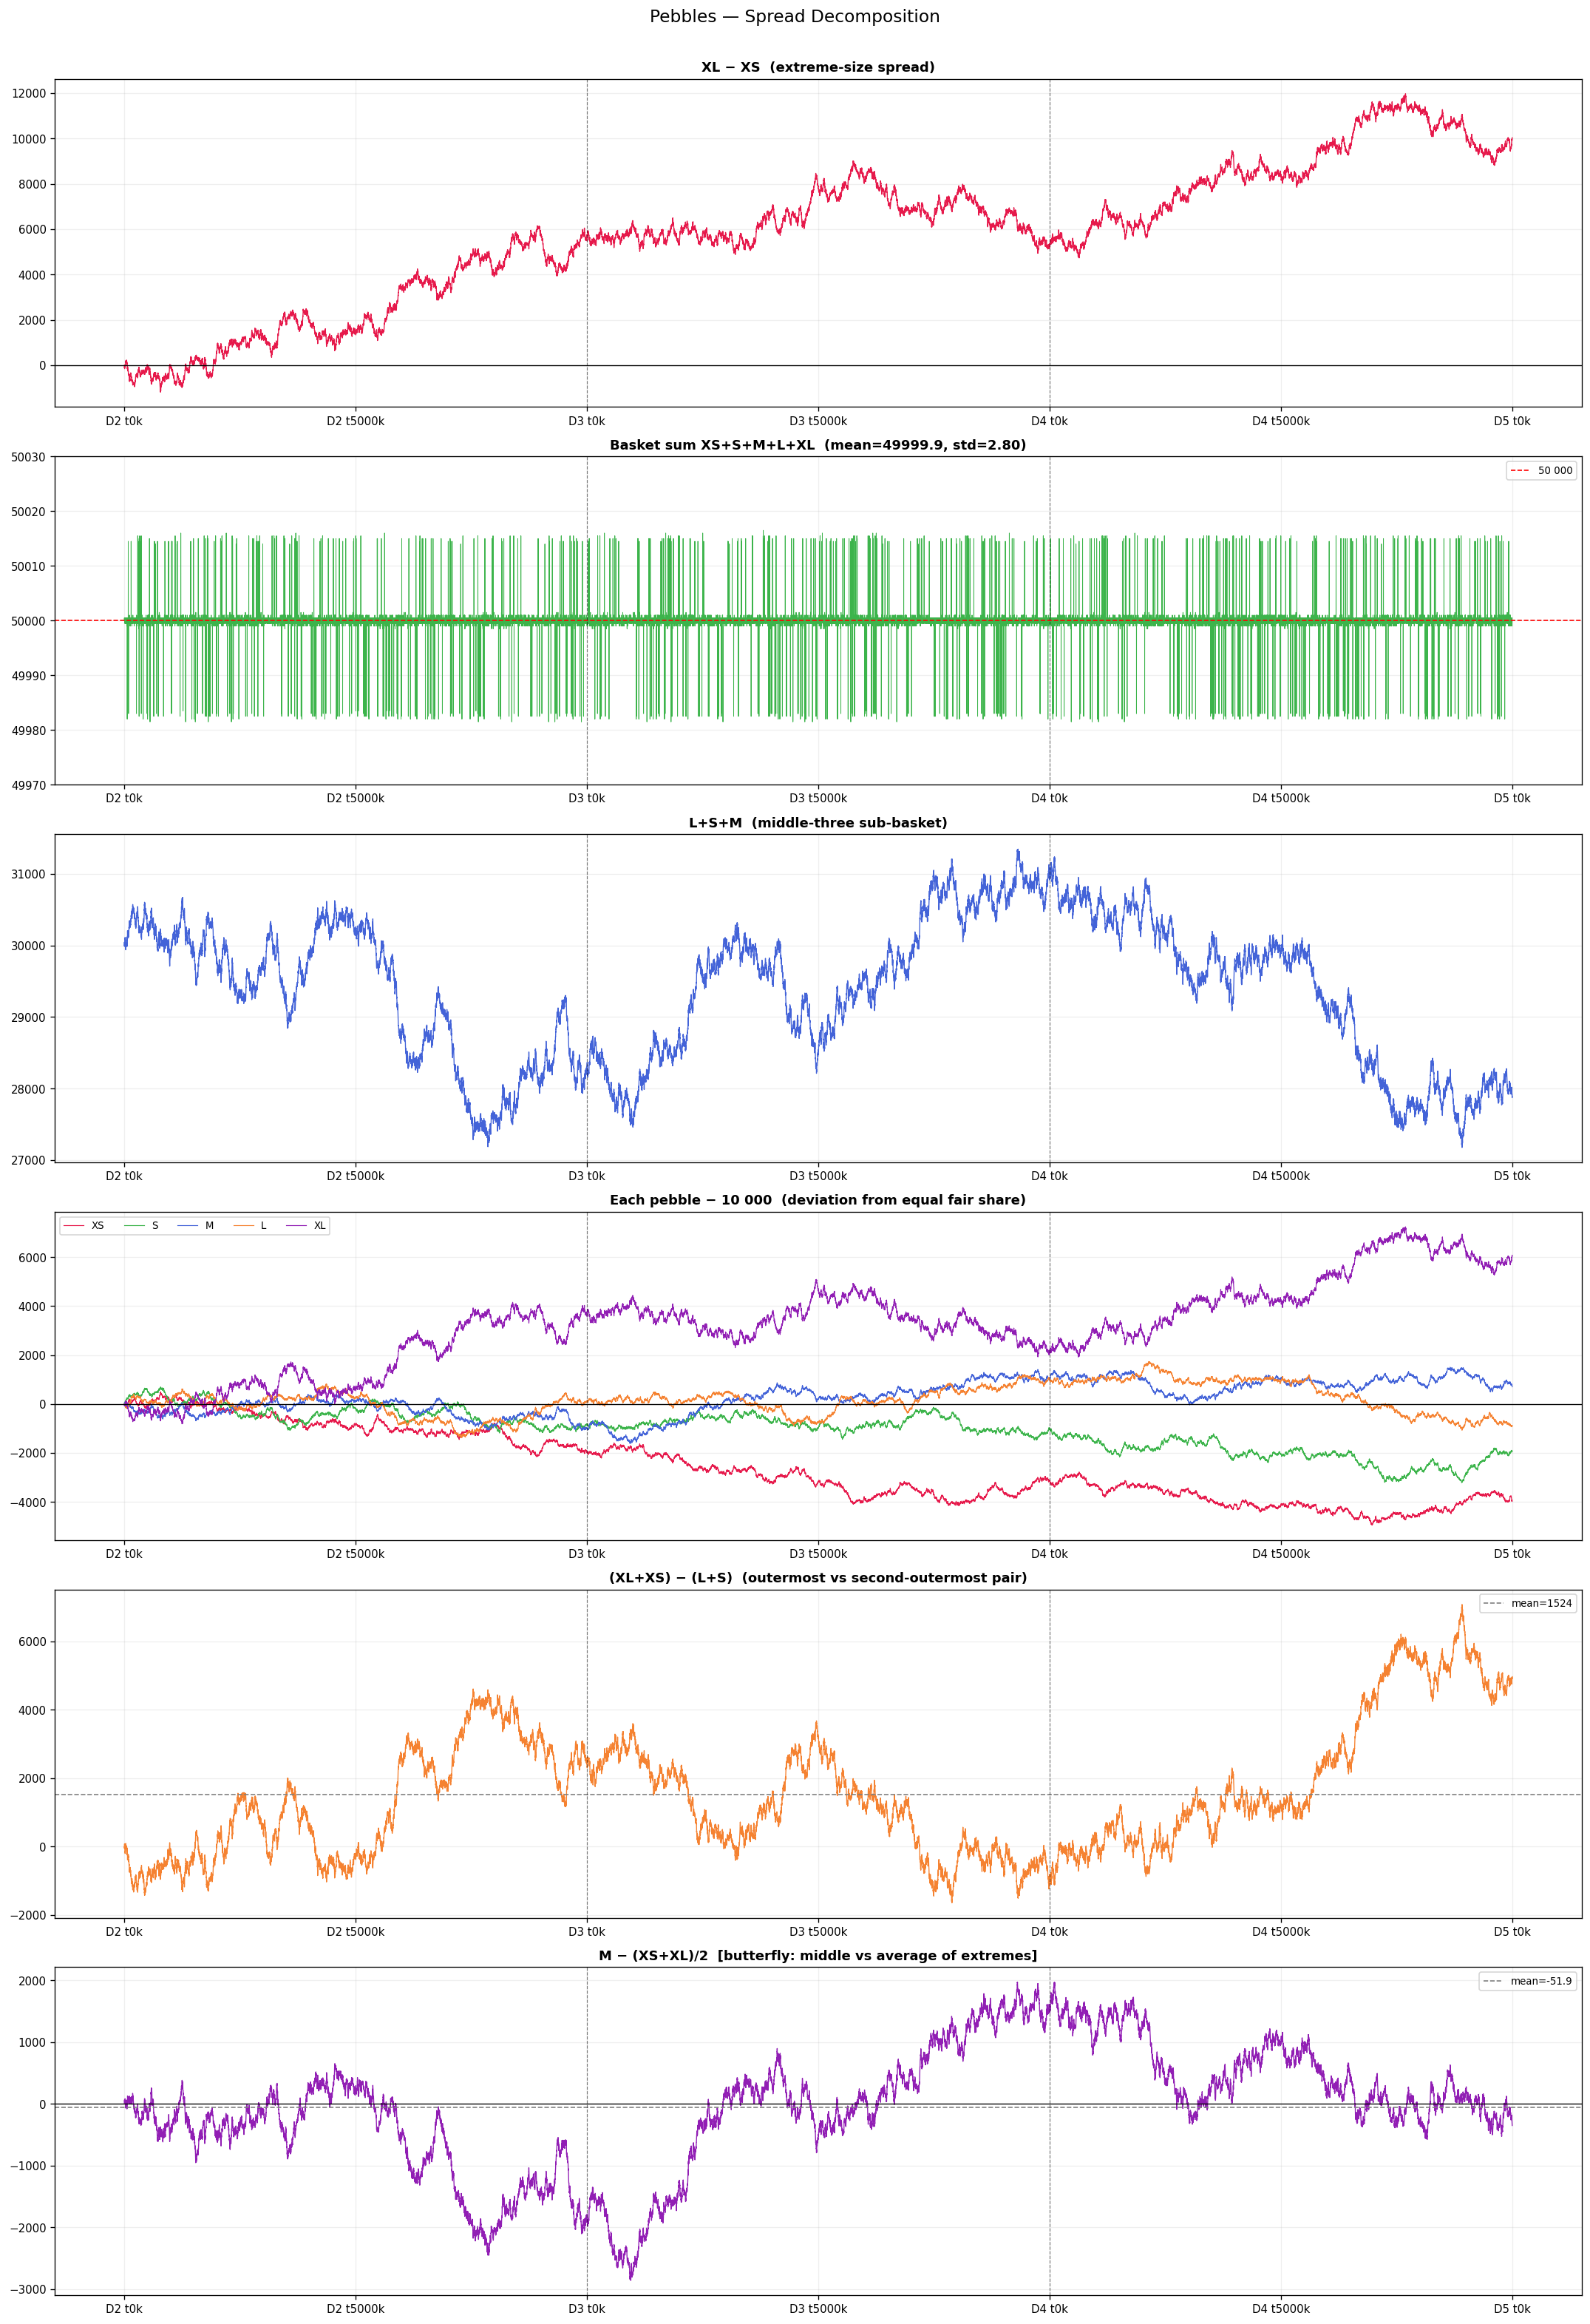

XL-XS          mean=+5820.9  std=3085.38
(XL+XS)-(L+S)  mean=+1523.8  std=1843.39
butterfly      mean=-51.9  std=992.77


In [2]:
XS = mid['PEBBLES_XS'].dropna()
S  = mid['PEBBLES_S'].dropna()
M  = mid['PEBBLES_M'].dropna()
L  = mid['PEBBLES_L'].dropna()
XL = mid['PEBBLES_XL'].dropna()
peb_idx = XS.index  # all pebbles share the same timestamps

SERIES = [
    ('XL − XS',                   XL - XS,                    '#e6194b'),
    ('XS+S+M+L+XL (basket sum)',   XS+S+M+L+XL,               '#3cb44b'),
    ('L+S+M',                       L+S+M,                      '#4363d8'),
    ('Per-pebble − 10 000',         None,                       None),     # multi-line, handled below
    ('(XL+XS) − (L+S)',             (XL+XS) - (L+S),           '#f58231'),
    ('M − (XS+XL)/2  [butterfly]',  M - (XS+XL)/2,             '#911eb4'),
]

fig, axes = plt.subplots(6, 1, figsize=(18, 26))

def _vlines(ax):
    for ds in day_starts[1:]:
        ax.axvline(ds, color='black', linestyle='--', linewidth=0.7, alpha=0.5)

def _fmt(ax):
    ax.xaxis.set_major_formatter(mticker.FuncFormatter(
        lambda x, _: f'D{DAYS[0] + int(x // 1_000_000)} t{int(x % 1_000_000 // 100)}k'))
    ax.grid(True, alpha=0.2)

# 1 — XL - XS
axes[0].plot(peb_idx, (XL - XS).values, color='#e6194b', linewidth=0.8)
axes[0].axhline(0, color='black', linewidth=0.8)
axes[0].set_title('XL − XS  (extreme-size spread)', fontweight='bold')
_vlines(axes[0]); _fmt(axes[0])

# 2 — Basket sum
bsum = (XS + S + M + L + XL)
axes[1].plot(peb_idx, bsum.values, color='#3cb44b', linewidth=0.6)
axes[1].axhline(50000, color='red', linestyle='--', linewidth=1, label='50 000')
axes[1].set_title(f'Basket sum XS+S+M+L+XL  (mean={bsum.mean():.1f}, std={bsum.std():.2f})',
                  fontweight='bold')
axes[1].set_ylim(49970, 50030)
axes[1].legend(fontsize=8)
_vlines(axes[1]); _fmt(axes[1])

# 3 — L+S+M
lsm = L + S + M
axes[2].plot(peb_idx, lsm.values, color='#4363d8', linewidth=0.8)
axes[2].set_title('L+S+M  (middle-three sub-basket)', fontweight='bold')
_vlines(axes[2]); _fmt(axes[2])

# 4 — Per-pebble deviation from equal fair share (10 000)
EQUAL = 10_000
peb_devs = {'XS': XS-EQUAL, 'S': S-EQUAL, 'M': M-EQUAL, 'L': L-EQUAL, 'XL': XL-EQUAL}
for (name, dev), col in zip(peb_devs.items(), COLORS5):
    axes[3].plot(peb_idx, dev.values, color=col, linewidth=0.7, label=name)
axes[3].axhline(0, color='black', linewidth=0.8)
axes[3].set_title('Each pebble − 10 000  (deviation from equal fair share)', fontweight='bold')
axes[3].legend(ncol=5, fontsize=8)
_vlines(axes[3]); _fmt(axes[3])

# 5 — (XL+XS) - (L+S): outermost pair vs second-outermost pair
outer_vs_inner = (XL + XS) - (L + S)
axes[4].plot(peb_idx, outer_vs_inner.values, color='#f58231', linewidth=0.8)
axes[4].axhline(outer_vs_inner.mean(), color='grey', linestyle='--', linewidth=1,
                label=f'mean={outer_vs_inner.mean():.0f}')
axes[4].set_title('(XL+XS) − (L+S)  (outermost vs second-outermost pair)', fontweight='bold')
axes[4].legend(fontsize=8)
_vlines(axes[4]); _fmt(axes[4])

# 6 — M - (XS+XL)/2: butterfly (middle vs average of extremes)
butterfly = M - (XS + XL) / 2
axes[5].plot(peb_idx, butterfly.values, color='#911eb4', linewidth=0.8)
axes[5].axhline(0, color='black', linewidth=0.8)
axes[5].axhline(butterfly.mean(), color='grey', linestyle='--', linewidth=1,
                label=f'mean={butterfly.mean():.1f}')
axes[5].set_title('M − (XS+XL)/2  [butterfly: middle vs average of extremes]',
                  fontweight='bold')
axes[5].legend(fontsize=8)
_vlines(axes[5]); _fmt(axes[5])

fig.suptitle('Pebbles — Spread Decomposition', fontsize=14, y=1.005)
plt.tight_layout()
plt.show()

print(f'XL-XS          mean={( XL-XS).mean():+.1f}  std={(XL-XS).std():.2f}')
print(f'(XL+XS)-(L+S)  mean={outer_vs_inner.mean():+.1f}  std={outer_vs_inner.std():.2f}')
print(f'butterfly      mean={butterfly.mean():+.1f}  std={butterfly.std():.2f}')


L+S+M
  AC1=+0.0063  AC2=-0.0041  AC3=-0.0007
  Interpretation: near-random
Butterfly (M-(XS+XL)/2)
  AC1=+0.0021  AC2=+0.0020  AC3=+0.0003
  Interpretation: near-random


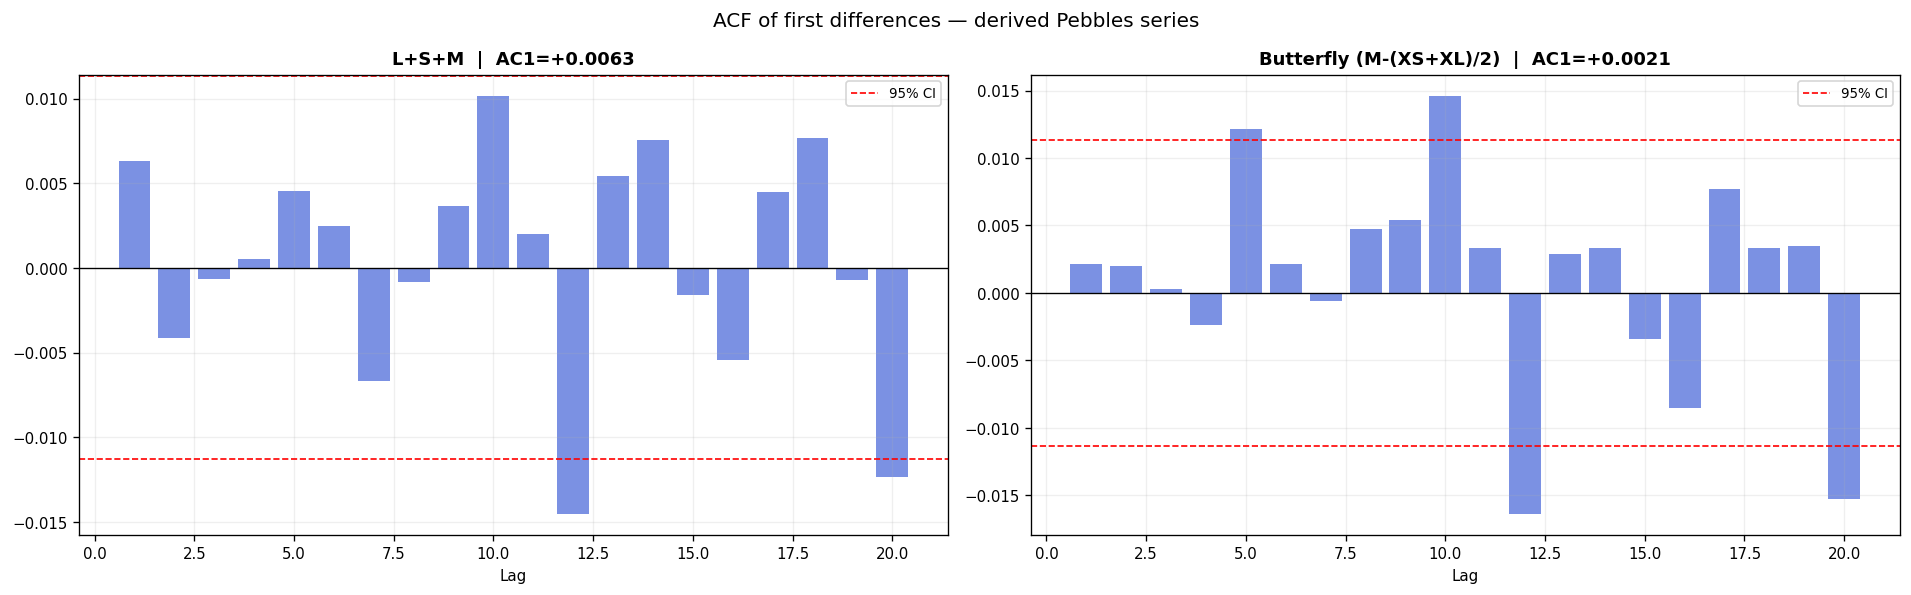

In [3]:
from statsmodels.tsa.stattools import acf

MAX_LAG = 20
series_to_test = {
    'L+S+M':                  L + S + M,
    'Butterfly (M-(XS+XL)/2)': M - (XS + XL) / 2,
}

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
conf = 1.96 / np.sqrt(len(peb_idx))

for ax, (name, s) in zip(axes, series_to_test.items()):
    a = acf(s.diff().dropna(), nlags=MAX_LAG, fft=True)
    ax.bar(range(1, MAX_LAG + 1), a[1:], color='#4363d8', alpha=0.7)
    ax.axhline(0,     color='black', linewidth=0.8)
    ax.axhline( conf, color='red',   linewidth=1, linestyle='--', label='95% CI')
    ax.axhline(-conf, color='red',   linewidth=1, linestyle='--')
    ax.set_title(f'{name}  |  AC1={a[1]:+.4f}', fontweight='bold')
    ax.set_xlabel('Lag')
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.2)
    print(f'{name}')
    print(f'  AC1={a[1]:+.4f}  AC2={a[2]:+.4f}  AC3={a[3]:+.4f}')
    interp = "mean-reverting" if a[1] < -conf else "trending" if a[1] > conf else "near-random"
    print(f'  Interpretation: {interp}')

plt.suptitle('ACF of first differences — derived Pebbles series', fontsize=12)
plt.tight_layout()
plt.show()


## Basket Arb Strategy: Trading the Sum=50,000 Constraint
At each tick, XS+S+M+L+XL must equal 50,000. This means deviation from an equal fair share of 10,000 is guaranteed to revert.
Plot: z-scores of each pebbles deviation, with buy/sell thresholds.

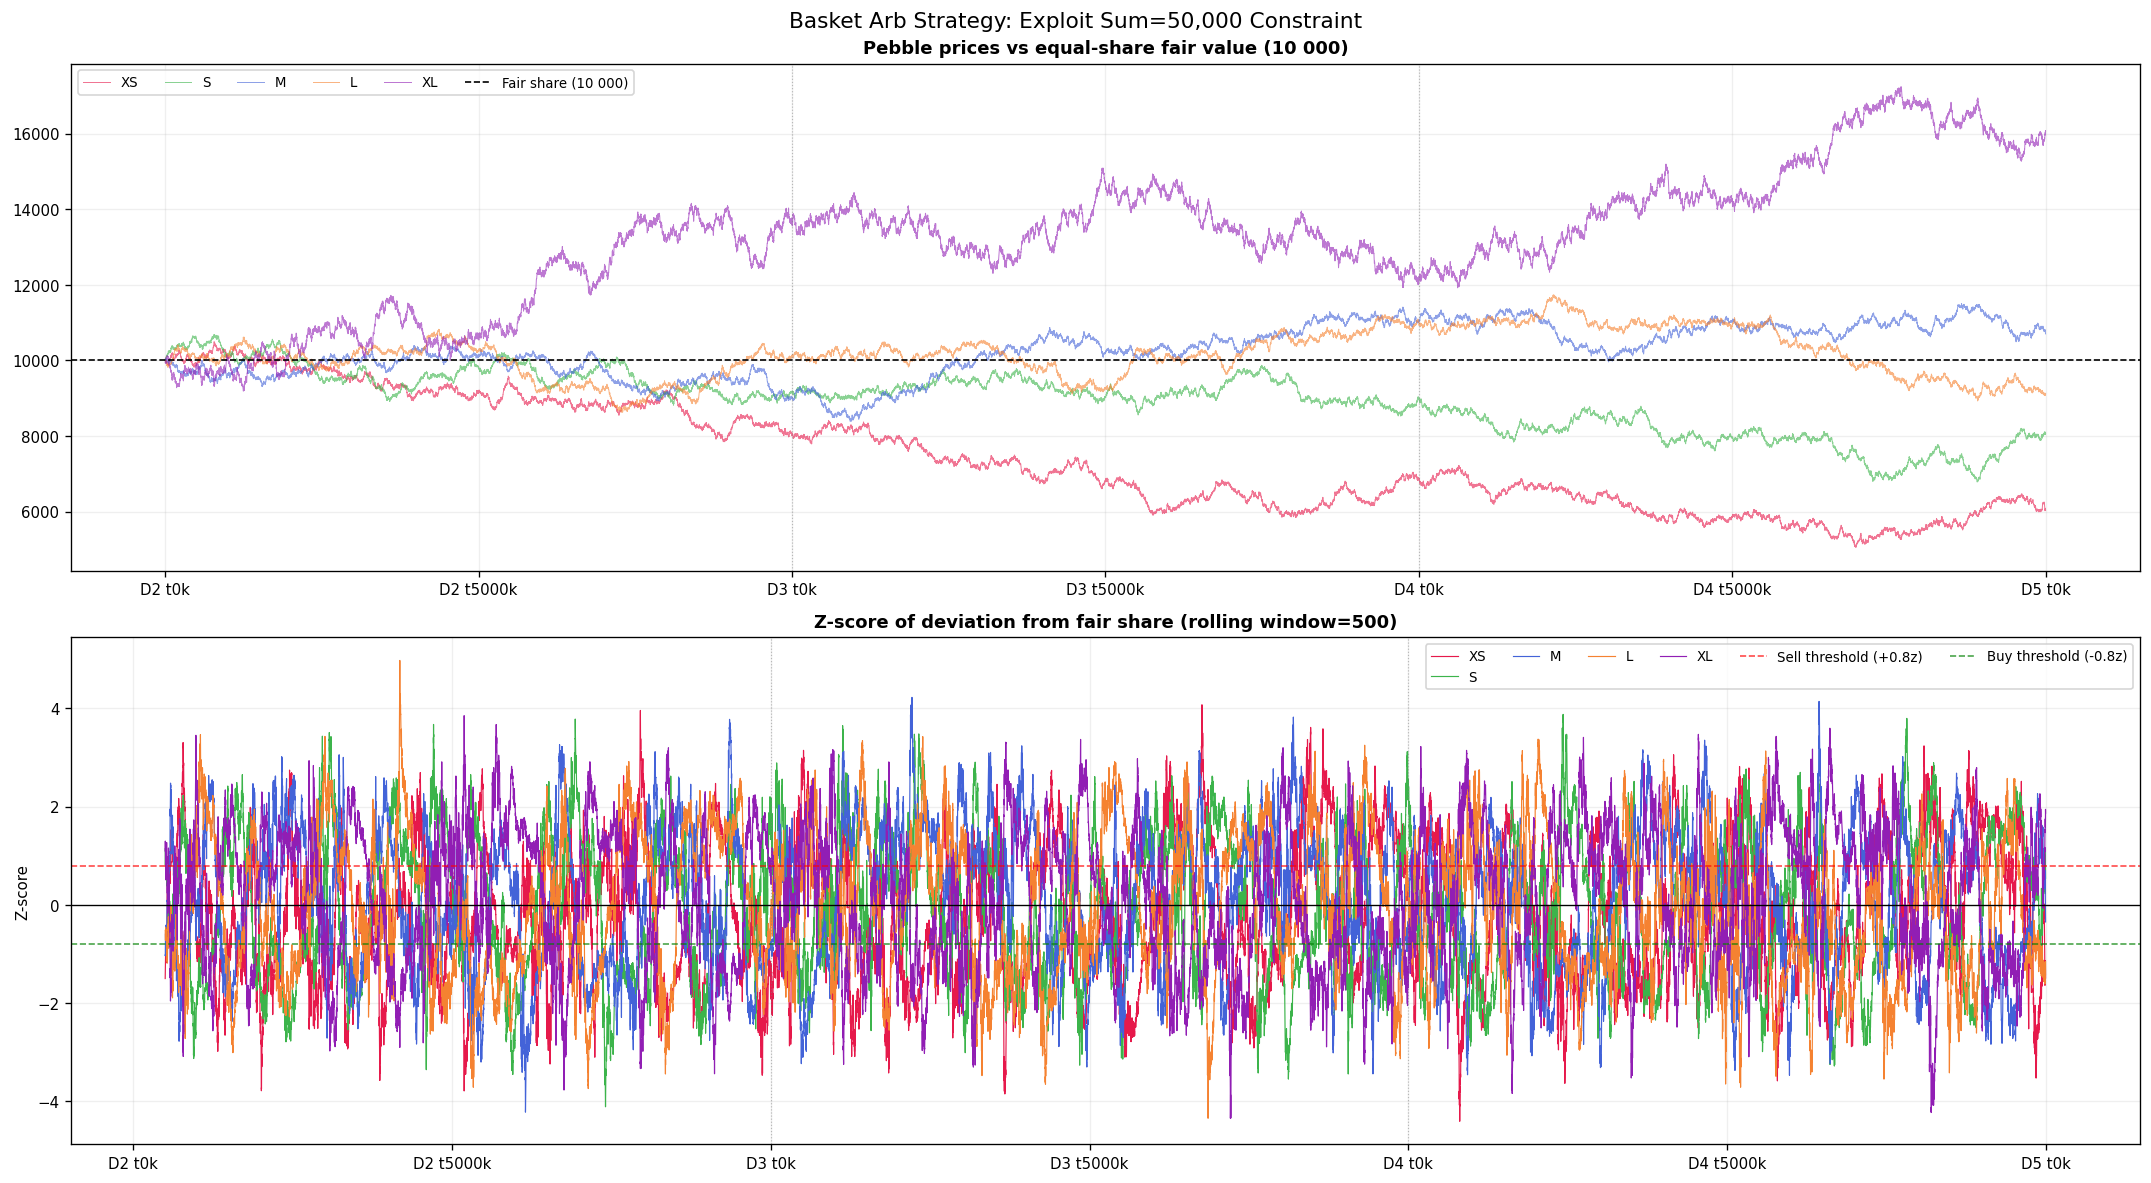

Entry signals: buy when z-score < -0.8, sell when z-score > 0.8
Position limit per product: 10 units
Max basket arb exposure: 50 units (all 5 pebbles at limit simultaneously)


In [4]:
FAIR_SHARE = 10_000
ENTRY_Z = 0.8  # entry threshold: enter when |z-score| > 0.8

# Compute rolling mean and std of deviations
window = 500  # 500-tick rolling window for z-score baseline
pebbles_dict = {'XS': XS, 'S': S, 'M': M, 'L': L, 'XL': XL}

fig, axes = plt.subplots(2, 1, figsize=(18, 10))

# Top: raw prices with fair share baseline
for (name, p), col in zip(pebbles_dict.items(), COLORS5):
    axes[0].plot(peb_idx, p.values, color=col, linewidth=0.6, alpha=0.6, label=name)
axes[0].axhline(FAIR_SHARE, color='black', linestyle='--', linewidth=1, label='Fair share (10 000)')
for ds in day_starts[1:]:
    axes[0].axvline(ds, color='gray', linestyle=':', linewidth=0.7, alpha=0.5)
axes[0].set_title('Pebble prices vs equal-share fair value (10 000)', fontweight='bold')
axes[0].legend(ncol=6, fontsize=8)
axes[0].grid(True, alpha=0.2)
axes[0].xaxis.set_major_formatter(mticker.FuncFormatter(
    lambda x, _: f'D{DAYS[0] + int(x // 1_000_000)} t{int(x % 1_000_000 // 100)}k'))

# Bottom: z-scores of deviation from fair share with buy/sell signals
for (name, p), col in zip(pebbles_dict.items(), COLORS5):
    dev = p - FAIR_SHARE
    # Rolling mean and std of the deviation
    rolling_mean = dev.rolling(window=window, center=False).mean()
    rolling_std  = dev.rolling(window=window, center=False).std().clip(lower=1)  # avoid div by 0
    z_score = (dev - rolling_mean) / rolling_std
    
    axes[1].plot(peb_idx, z_score.values, color=col, linewidth=0.7, label=name)

# Add threshold bands
axes[1].axhline( ENTRY_Z, color='red',   linestyle='--', linewidth=1, alpha=0.7, label=f'Sell threshold (+{ENTRY_Z}z)')
axes[1].axhline(-ENTRY_Z, color='green', linestyle='--', linewidth=1, alpha=0.7, label=f'Buy threshold (-{ENTRY_Z}z)')
axes[1].axhline(0,        color='black', linestyle='-',  linewidth=0.8)

for ds in day_starts[1:]:
    axes[1].axvline(ds, color='gray', linestyle=':', linewidth=0.7, alpha=0.5)

axes[1].set_title(f'Z-score of deviation from fair share (rolling window={window})', fontweight='bold')
axes[1].set_ylabel('Z-score')
axes[1].legend(ncol=6, fontsize=8)
axes[1].grid(True, alpha=0.2)
axes[1].xaxis.set_major_formatter(mticker.FuncFormatter(
    lambda x, _: f'D{DAYS[0] + int(x // 1_000_000)} t{int(x % 1_000_000 // 100)}k'))

plt.suptitle('Basket Arb Strategy: Exploit Sum=50,000 Constraint', fontsize=13)
plt.tight_layout()
plt.show()

print(f"Entry signals: buy when z-score < {-ENTRY_Z}, sell when z-score > {ENTRY_Z}")
print(f"Position limit per product: 10 units")
print(f"Max basket arb exposure: 50 units (all 5 pebbles at limit simultaneously)")


## Hedge Strategy: XL-XS and Butterfly (Negative Correlation)
Hypothesis: when XL-XS trends up (XL expensive relative to XS), butterfly trends down (M cheap relative to extremes). Test correlation and design a hedged pairs trade.

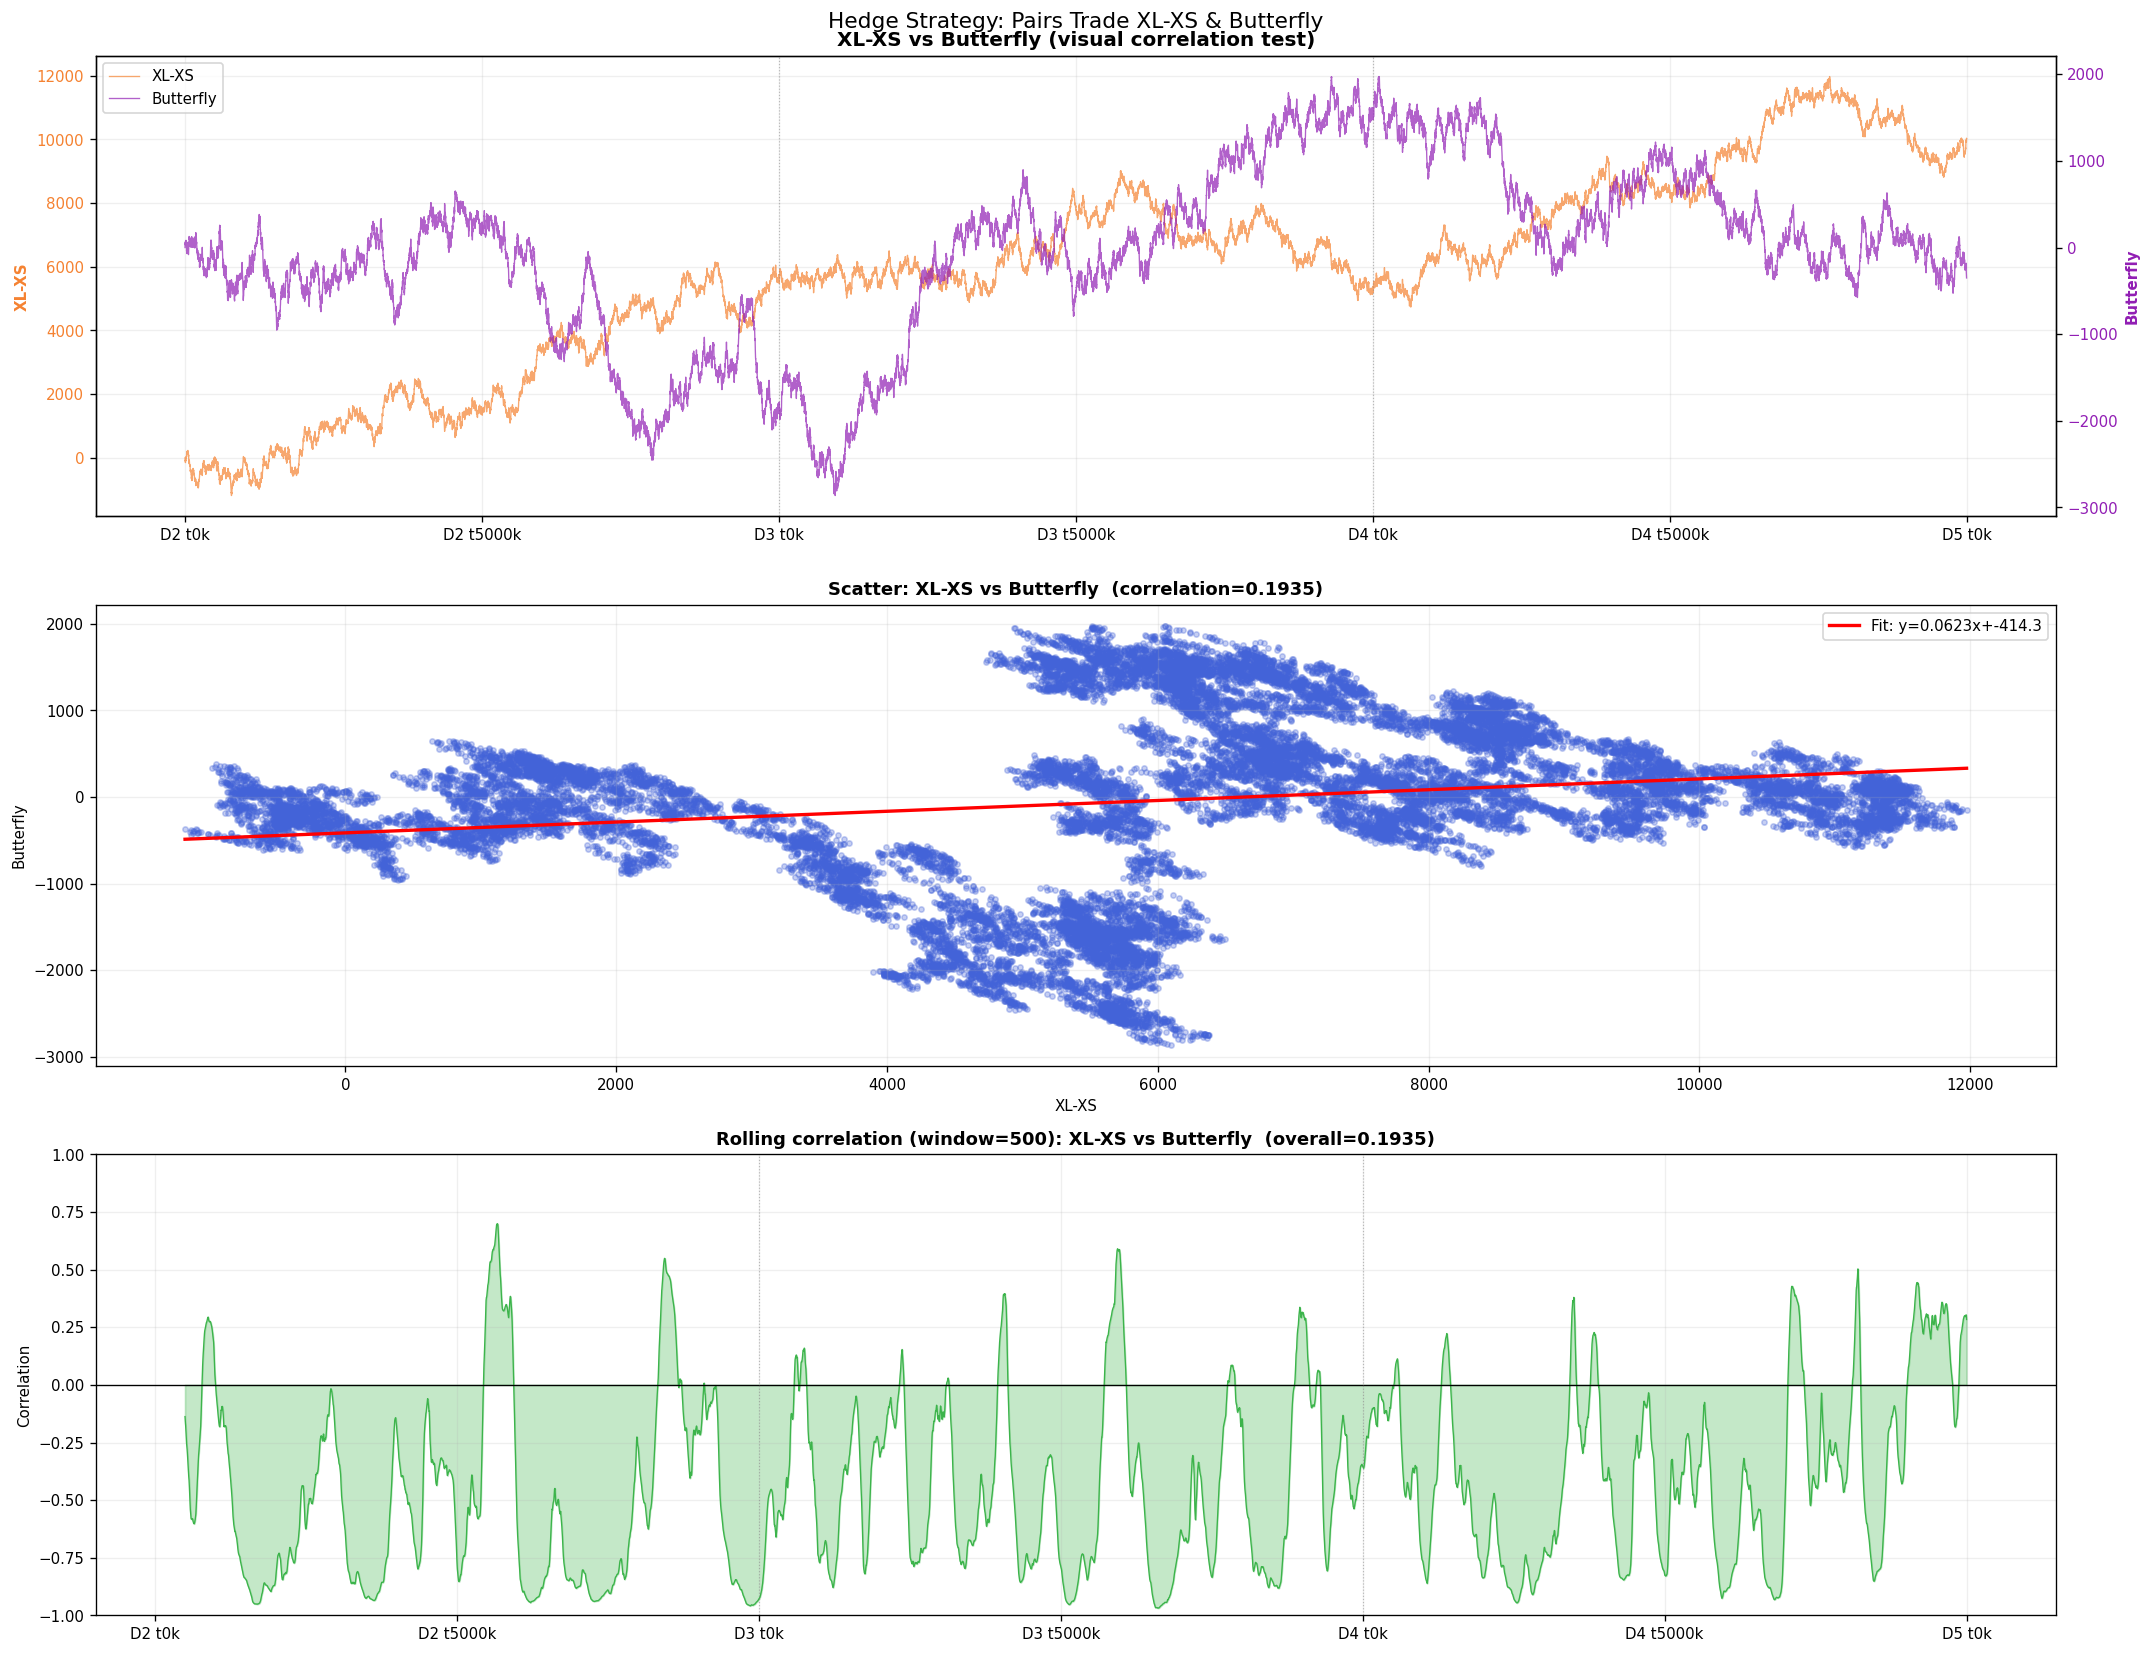

Overall correlation (XL-XS, Butterfly): 0.1935
Linear fit: Butterfly ≈ 0.0623 * (XL-XS) + -414.3

If correlation is negative: pairs trade is hedged.
Position: LONG Butterfly, SHORT XL-XS when both are large.
Rationale: profit from mean reversion of the spread without directional risk.


In [5]:
xl_xs = XL - XS
butterfly = M - (XS + XL) / 2

fig, axes = plt.subplots(3, 1, figsize=(18, 14))

# 1 — XL-XS and butterfly on same plot (dual y-axis)
ax1 = axes[0]
ax2 = ax1.twinx()

line1 = ax1.plot(peb_idx, xl_xs.values, color='#f58231', linewidth=0.8, label='XL-XS', alpha=0.7)
line2 = ax2.plot(peb_idx, butterfly.values, color='#911eb4', linewidth=0.8, label='Butterfly', alpha=0.7)

for ds in day_starts[1:]:
    ax1.axvline(ds, color='gray', linestyle=':', linewidth=0.7, alpha=0.5)

ax1.set_title('XL-XS vs Butterfly (visual correlation test)', fontweight='bold', fontsize=12)
ax1.set_ylabel('XL-XS', color='#f58231', fontweight='bold')
ax2.set_ylabel('Butterfly', color='#911eb4', fontweight='bold')
ax1.tick_params(axis='y', labelcolor='#f58231')
ax2.tick_params(axis='y', labelcolor='#911eb4')
ax1.grid(True, alpha=0.2)
ax1.xaxis.set_major_formatter(mticker.FuncFormatter(
    lambda x, _: f'D{DAYS[0] + int(x // 1_000_000)} t{int(x % 1_000_000 // 100)}k'))

lines = line1 + line2
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc='upper left', fontsize=9)

# 2 — Scatter plot: XL-XS vs butterfly
axes[1].scatter(xl_xs.values, butterfly.values, alpha=0.3, s=10, color='#4363d8')
z = np.polyfit(xl_xs.dropna().values, butterfly[xl_xs.index].dropna().values, 1)
p = np.poly1d(z)
x_line = np.linspace(xl_xs.min(), xl_xs.max(), 100)
axes[1].plot(x_line, p(x_line), "r-", linewidth=2, label=f'Fit: y={z[0]:.4f}x+{z[1]:.1f}')
corr = xl_xs.corr(butterfly)
axes[1].set_title(f'Scatter: XL-XS vs Butterfly  (correlation={corr:.4f})', fontweight='bold')
axes[1].set_xlabel('XL-XS')
axes[1].set_ylabel('Butterfly')
axes[1].legend(fontsize=9)
axes[1].grid(True, alpha=0.2)

# 3 — Rolling correlation (window=500)
rolling_corr = xl_xs.rolling(window=500).corr(butterfly)
axes[2].plot(peb_idx, rolling_corr.values, color='#3cb44b', linewidth=0.8)
axes[2].axhline(0, color='black', linewidth=0.8)
axes[2].fill_between(peb_idx, rolling_corr.values, 0, alpha=0.3, color='#3cb44b')

for ds in day_starts[1:]:
    axes[2].axvline(ds, color='gray', linestyle=':', linewidth=0.7, alpha=0.5)

axes[2].set_title(f'Rolling correlation (window=500): XL-XS vs Butterfly  (overall={corr:.4f})',
                  fontweight='bold')
axes[2].set_ylabel('Correlation')
axes[2].set_ylim(-1, 1)
axes[2].grid(True, alpha=0.2)
axes[2].xaxis.set_major_formatter(mticker.FuncFormatter(
    lambda x, _: f'D{DAYS[0] + int(x // 1_000_000)} t{int(x % 1_000_000 // 100)}k'))

plt.suptitle('Hedge Strategy: Pairs Trade XL-XS & Butterfly', fontsize=13)
plt.tight_layout()
plt.show()

print(f"Overall correlation (XL-XS, Butterfly): {corr:.4f}")
print(f"Linear fit: Butterfly ≈ {z[0]:.4f} * (XL-XS) + {z[1]:.1f}")
print(f"\nIf correlation is negative: pairs trade is hedged.")
print(f"Position: LONG Butterfly, SHORT XL-XS when both are large.")
print(f"Rationale: profit from mean reversion of the spread without directional risk.")


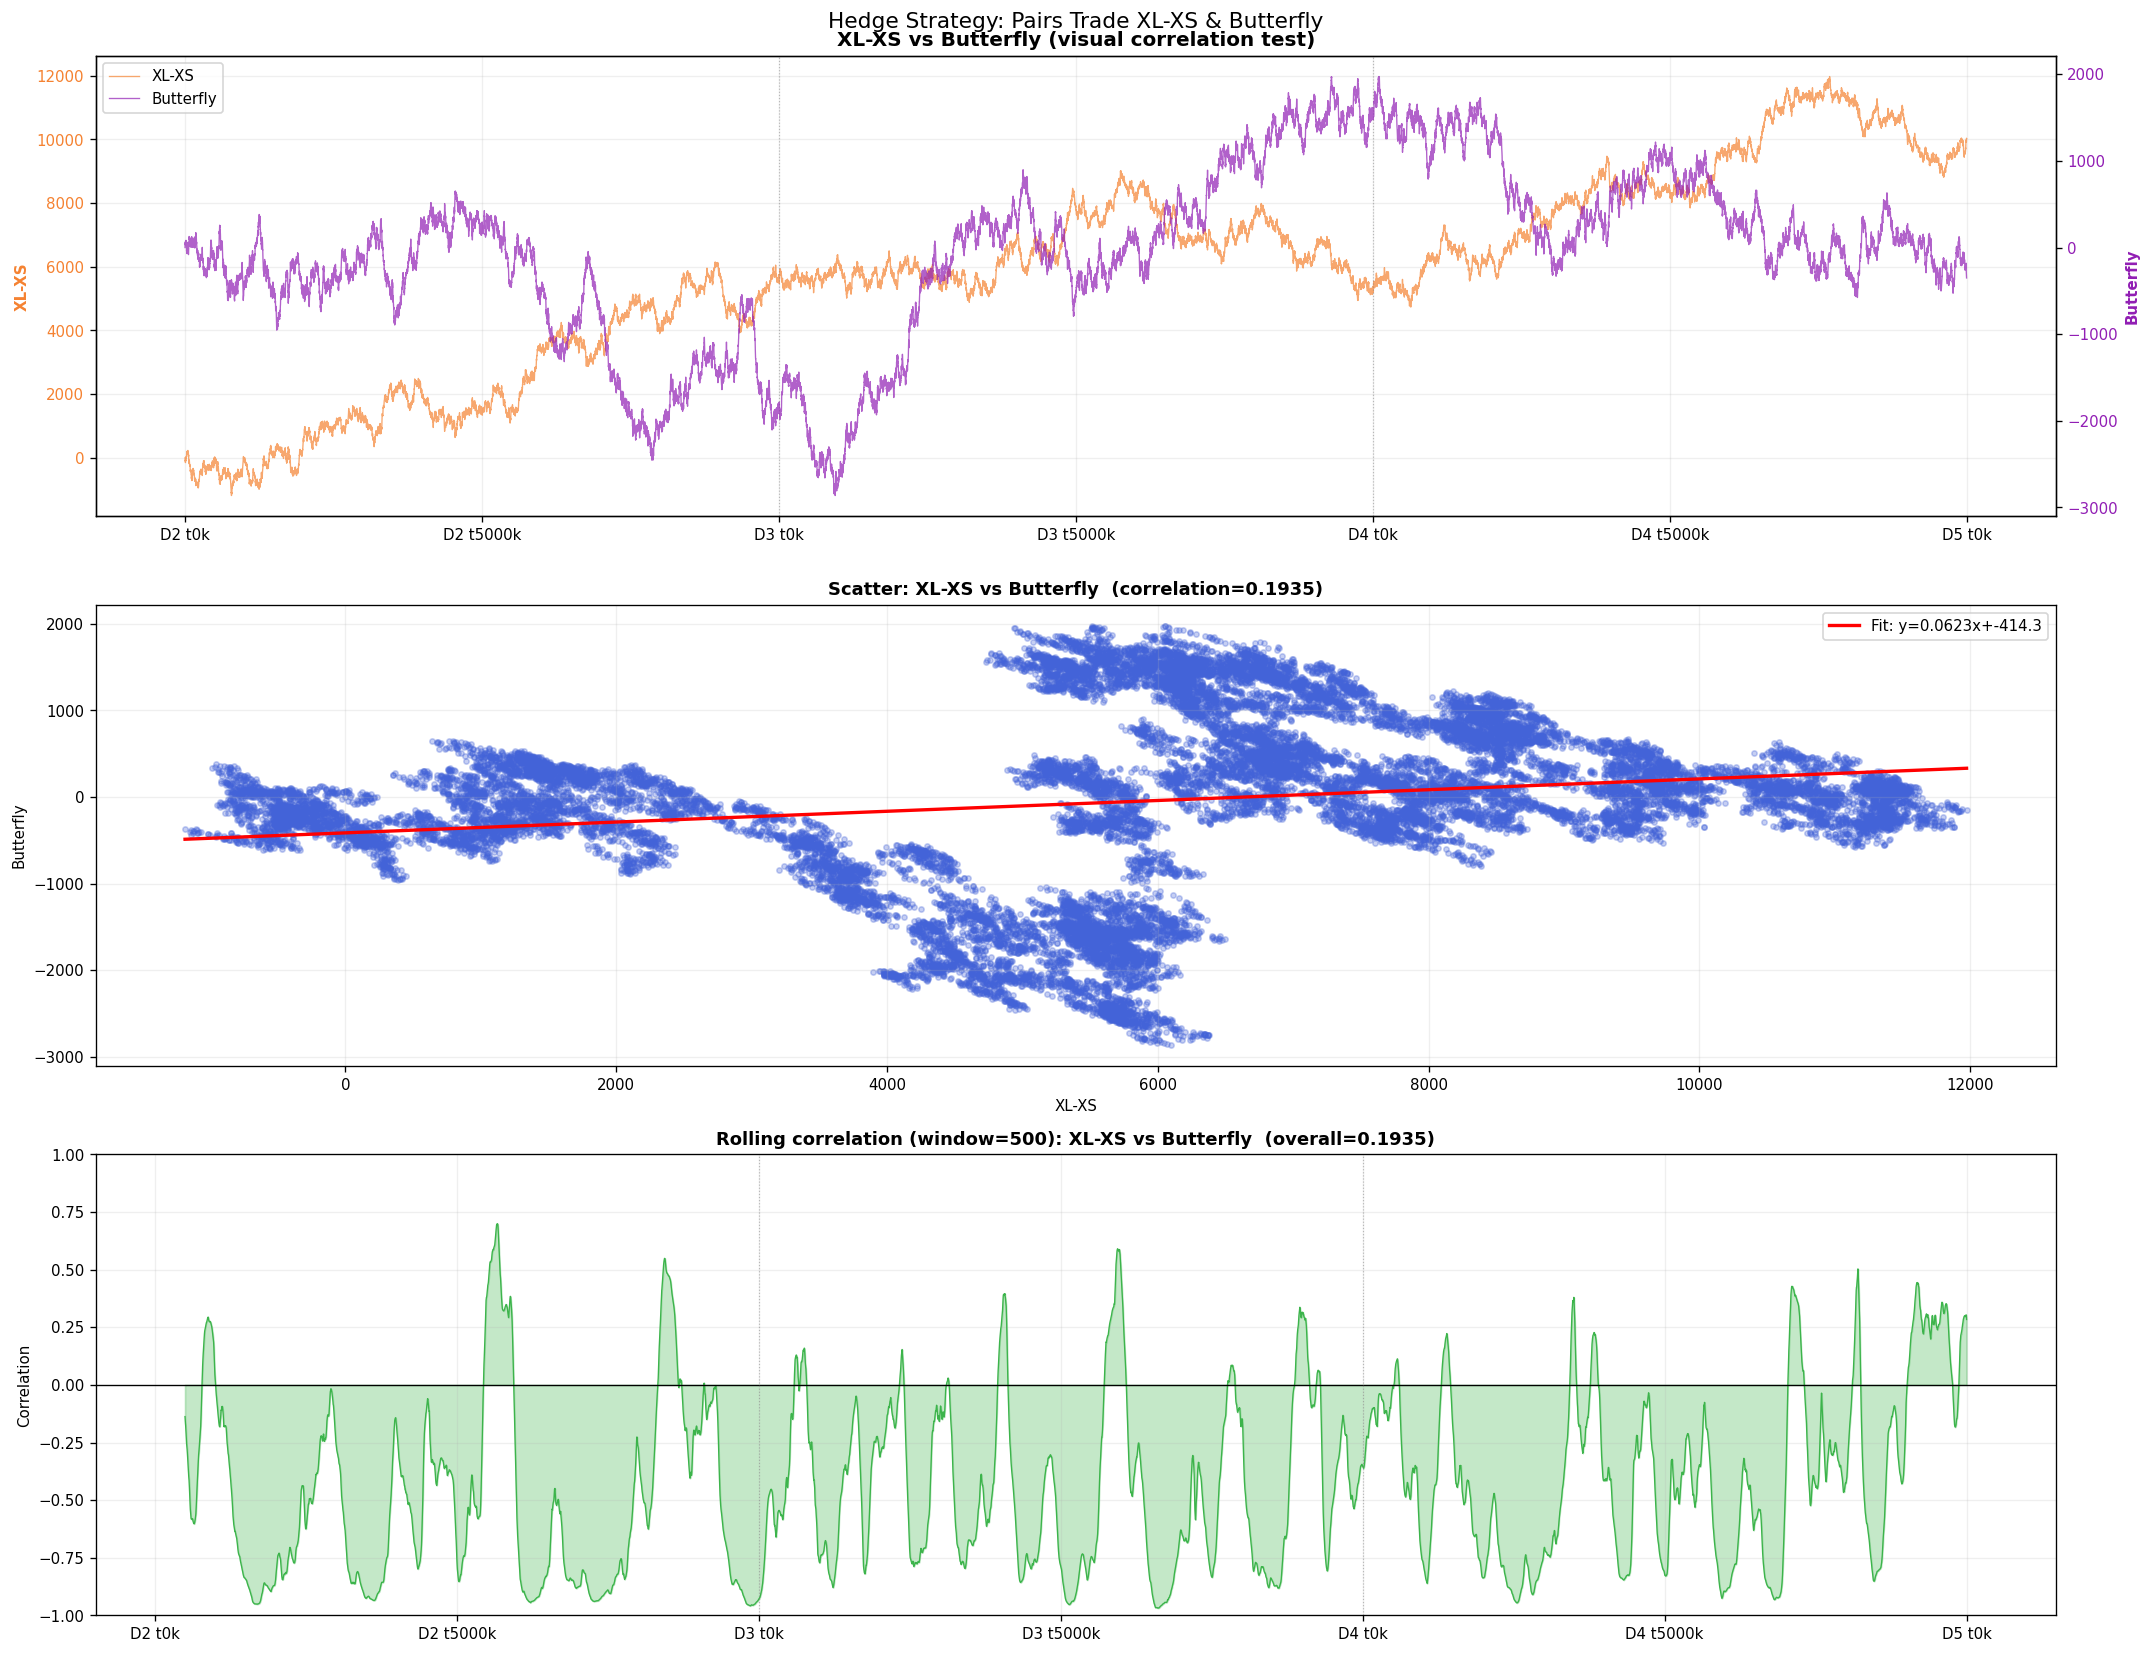

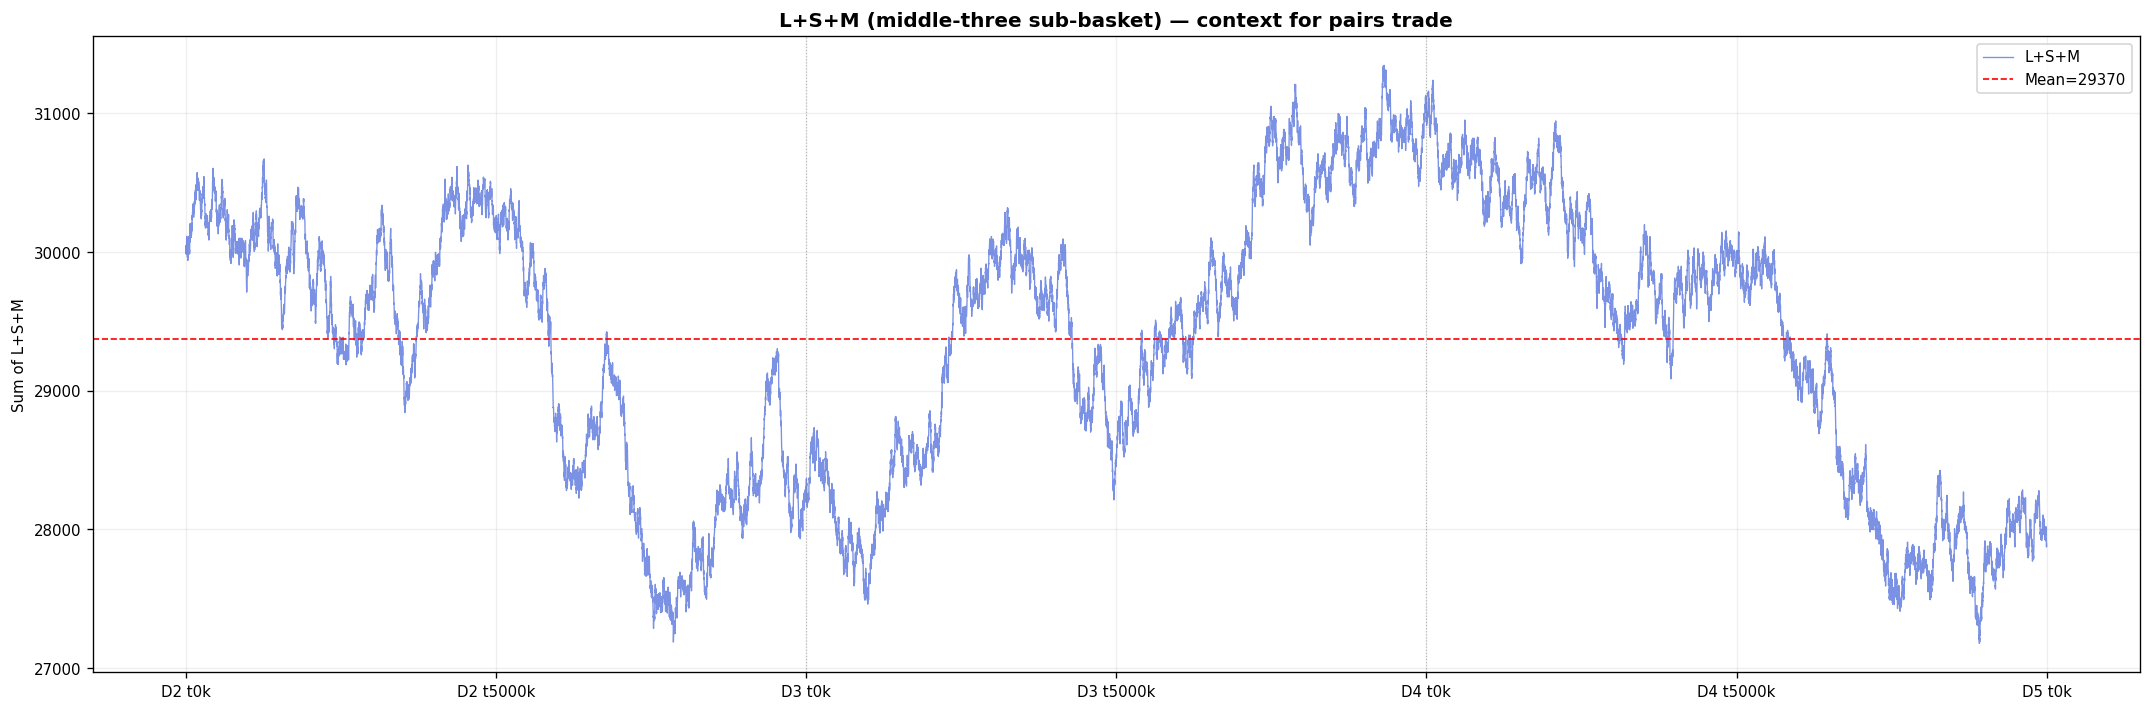

Overall correlation (XL-XS, Butterfly): 0.1935
Linear fit: Butterfly ≈ 0.0623 * (XL-XS) + -414.3

If correlation is negative: pairs trade is hedged.
Position: LONG Butterfly, SHORT XL-XS when both are large.
Rationale: profit from mean reversion of the spread without directional risk.


In [6]:
xl_xs = XL - XS
butterfly = M - (XS + XL) / 2

fig, axes = plt.subplots(3, 1, figsize=(18, 14))

# 1 — XL-XS and butterfly on same plot (dual y-axis)
ax1 = axes[0]
ax2 = ax1.twinx()

line1 = ax1.plot(peb_idx, xl_xs.values, color='#f58231', linewidth=0.8, label='XL-XS', alpha=0.7)
line2 = ax2.plot(peb_idx, butterfly.values, color='#911eb4', linewidth=0.8, label='Butterfly', alpha=0.7)

for ds in day_starts[1:]:
    ax1.axvline(ds, color='gray', linestyle=':', linewidth=0.7, alpha=0.5)

ax1.set_title('XL-XS vs Butterfly (visual correlation test)', fontweight='bold', fontsize=12)
ax1.set_ylabel('XL-XS', color='#f58231', fontweight='bold')
ax2.set_ylabel('Butterfly', color='#911eb4', fontweight='bold')
ax1.tick_params(axis='y', labelcolor='#f58231')
ax2.tick_params(axis='y', labelcolor='#911eb4')
ax1.grid(True, alpha=0.2)
ax1.xaxis.set_major_formatter(mticker.FuncFormatter(
    lambda x, _: f'D{DAYS[0] + int(x // 1_000_000)} t{int(x % 1_000_000 // 100)}k'))

lines = line1 + line2
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc='upper left', fontsize=9)

# 2 — Scatter plot: XL-XS vs butterfly
axes[1].scatter(xl_xs.values, butterfly.values, alpha=0.3, s=10, color='#4363d8')
z = np.polyfit(xl_xs.dropna().values, butterfly[xl_xs.index].dropna().values, 1)
p = np.poly1d(z)
x_line = np.linspace(xl_xs.min(), xl_xs.max(), 100)
axes[1].plot(x_line, p(x_line), "r-", linewidth=2, label=f'Fit: y={z[0]:.4f}x+{z[1]:.1f}')
corr = xl_xs.corr(butterfly)
axes[1].set_title(f'Scatter: XL-XS vs Butterfly  (correlation={corr:.4f})', fontweight='bold')
axes[1].set_xlabel('XL-XS')
axes[1].set_ylabel('Butterfly')
axes[1].legend(fontsize=9)
axes[1].grid(True, alpha=0.2)

# 3 — Rolling correlation (window=500)
rolling_corr = xl_xs.rolling(window=500).corr(butterfly)
axes[2].plot(peb_idx, rolling_corr.values, color='#3cb44b', linewidth=0.8)
axes[2].axhline(0, color='black', linewidth=0.8)
axes[2].fill_between(peb_idx, rolling_corr.values, 0, alpha=0.3, color='#3cb44b')

for ds in day_starts[1:]:
    axes[2].axvline(ds, color='gray', linestyle=':', linewidth=0.7, alpha=0.5)

axes[2].set_title(f'Rolling correlation (window=500): XL-XS vs Butterfly  (overall={corr:.4f})',
                  fontweight='bold')
axes[2].set_ylabel('Correlation')
axes[2].set_ylim(-1, 1)
axes[2].grid(True, alpha=0.2)
axes[2].xaxis.set_major_formatter(mticker.FuncFormatter(
    lambda x, _: f'D{DAYS[0] + int(x // 1_000_000)} t{int(x % 1_000_000 // 100)}k'))

plt.suptitle('Hedge Strategy: Pairs Trade XL-XS & Butterfly', fontsize=13)
plt.tight_layout()
plt.show()

# 4 — L+S+M (middle-three sub-basket) as separate figure
lsm = L + S + M
fig2, ax3 = plt.subplots(figsize=(18, 6))

ax3.plot(peb_idx, lsm.values, color='#4363d8', linewidth=0.8, label='L+S+M', alpha=0.7)
ax3.axhline(lsm.mean(), color='red', linestyle='--', linewidth=1, label=f'Mean={lsm.mean():.0f}')

for ds in day_starts[1:]:
    ax3.axvline(ds, color='gray', linestyle=':', linewidth=0.7, alpha=0.5)

ax3.set_title('L+S+M (middle-three sub-basket) — context for pairs trade', fontweight='bold', fontsize=12)
ax3.set_ylabel('Sum of L+S+M')
ax3.legend(fontsize=9)
ax3.grid(True, alpha=0.2)
ax3.xaxis.set_major_formatter(mticker.FuncFormatter(
    lambda x, _: f'D{DAYS[0] + int(x // 1_000_000)} t{int(x % 1_000_000 // 100)}k'))
plt.tight_layout()
plt.show()

print(f"Overall correlation (XL-XS, Butterfly): {corr:.4f}")
print(f"Linear fit: Butterfly ≈ {z[0]:.4f} * (XL-XS) + {z[1]:.1f}")
print(f"\nIf correlation is negative: pairs trade is hedged.")
print(f"Position: LONG Butterfly, SHORT XL-XS when both are large.")
print(f"Rationale: profit from mean reversion of the spread without directional risk.")


## ACF1 Analysis: XL-XS and Weighted Distance
Test whether the raw XL-XS spread or a ratio-weighted spread shows mean reversion.

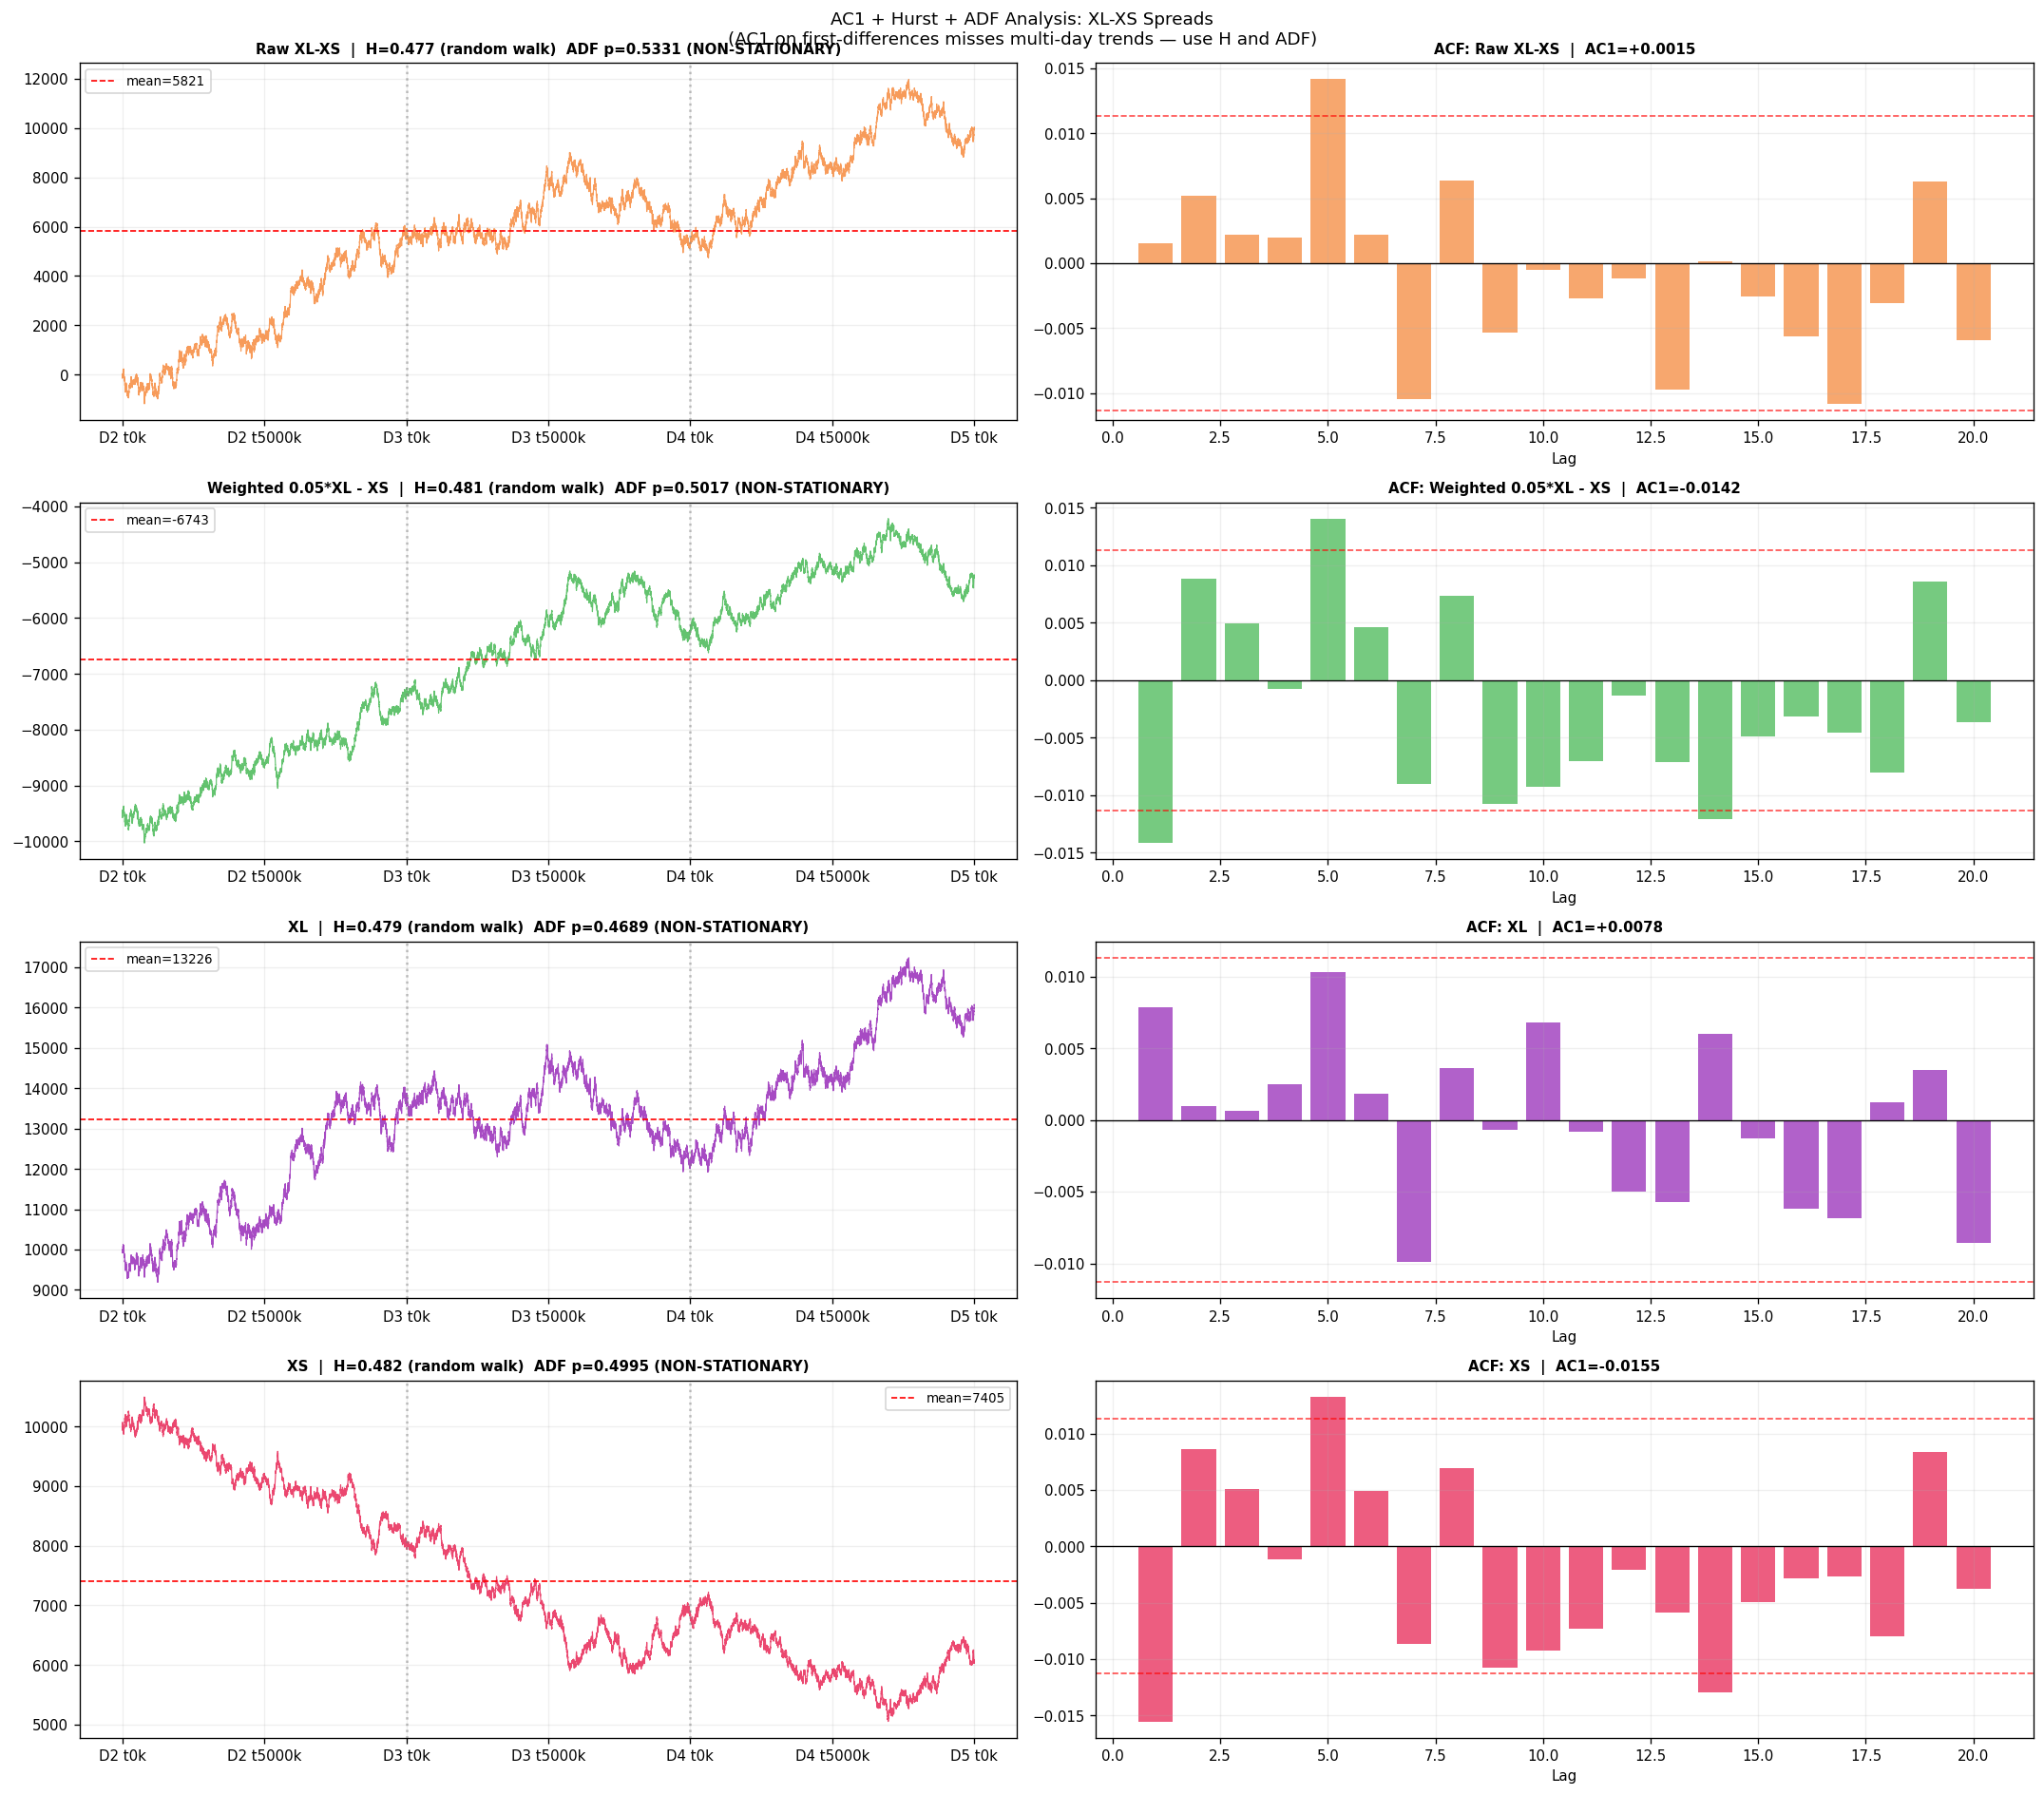

Series                                   AC1    Hurst H         Trend?      ADF p   Stationary?
-----------------------------------------------------------------------------------------------
Raw XL-XS                            +0.0015      0.477    random walk     0.5331 NON-STATIONARY
Weighted 0.05*XL - XS                -0.0142      0.481    random walk     0.5017 NON-STATIONARY
XL                                   +0.0078      0.479    random walk     0.4689 NON-STATIONARY
XS                                   -0.0155      0.482    random walk     0.4995 NON-STATIONARY

Key: H>0.55=trending | H<0.45=MR | ADF p>0.05=non-stationary
AC1 near zero on a visually trending series means the trend is slow (multi-day),
not that the series is random. Always cross-check with Hurst + ADF.


In [7]:
from statsmodels.tsa.stattools import acf, adfuller

# ── CONFIGURE HERE ───────────────────────────────────────────────────────────
RATIO = 0.05  # a/b for weighted spread: RATIO*XL - XS (change this to explore)
# ─────────────────────────────────────────────────────────────────────────────

MAX_LAG = 20

xl_xs_raw      = XL - XS
xl_xs_weighted = RATIO * XL - XS

def hurst(series, max_lag=100):
    # H < 0.5 = mean-reverting, H = 0.5 = random walk, H > 0.5 = trending
    lags = range(2, max_lag)
    tau  = [np.std(np.subtract(series[lag:], series[:-lag])) for lag in lags]
    poly = np.polyfit(np.log(lags), np.log(tau), 1)
    return poly[0]

def adf_pval(series):
    # p < 0.05 = stationary (no unit root = not persistently trending)
    return adfuller(series.dropna(), autolag="AIC")[1]

series_map = {
    "Raw XL-XS":                xl_xs_raw,
    f"Weighted {RATIO}*XL - XS": xl_xs_weighted,
    "XL":                        XL,
    "XS":                        XS,
}

fig, axes = plt.subplots(4, 2, figsize=(18, 16))
conf   = 1.96 / np.sqrt(len(peb_idx))
colors = ["#f58231", "#3cb44b", "#911eb4", "#e6194b"]

for row, ((name, s), col) in enumerate(zip(series_map.items(), colors)):
    H    = hurst(s.dropna().values)
    pval = adf_pval(s)
    a    = acf(s.diff().dropna(), nlags=MAX_LAG, fft=True)

    trend_str = "TRENDING"    if H > 0.55 else ("MR" if H < 0.45 else "random walk")
    stat_str  = "stationary"  if pval < 0.05 else "NON-STATIONARY"

    # Left: price series
    axes[row, 0].plot(peb_idx, s.values, color=col, linewidth=0.7, alpha=0.8)
    axes[row, 0].axhline(s.mean(), color="red", linestyle="--", linewidth=1,
                         label=f"mean={s.mean():.0f}")
    for ds in day_starts[1:]:
        axes[row, 0].axvline(ds, color="gray", linestyle=":", alpha=0.5)
    axes[row, 0].set_title(
        f"{name}  |  H={H:.3f} ({trend_str})  ADF p={pval:.4f} ({stat_str})",
        fontweight="bold", fontsize=9)
    axes[row, 0].legend(fontsize=8)
    axes[row, 0].grid(True, alpha=0.2)
    axes[row, 0].xaxis.set_major_formatter(mticker.FuncFormatter(
        lambda x, _: f"D{DAYS[0] + int(x // 1_000_000)} t{int(x % 1_000_000 // 100)}k"))

    # Right: ACF
    axes[row, 1].bar(range(1, MAX_LAG + 1), a[1:], color=col, alpha=0.7)
    axes[row, 1].axhline(0,     color="black", linewidth=0.8)
    axes[row, 1].axhline( conf, color="red",   linestyle="--", linewidth=1, alpha=0.7)
    axes[row, 1].axhline(-conf, color="red",   linestyle="--", linewidth=1, alpha=0.7)
    axes[row, 1].set_title(f"ACF: {name}  |  AC1={a[1]:+.4f}",
                           fontweight="bold", fontsize=9)
    axes[row, 1].set_xlabel("Lag")
    axes[row, 1].grid(True, alpha=0.2)

plt.suptitle(
    "AC1 + Hurst + ADF Analysis: XL-XS Spreads\n"
    "(AC1 on first-differences misses multi-day trends — use H and ADF)",
    fontsize=11)
plt.tight_layout()
plt.show()

header = f"{'Series':<35} {'AC1':>8} {'Hurst H':>10} {'Trend?':>14} {'ADF p':>10} {'Stationary?':>13}"
print(header)
print("-" * 95)
for (name, s) in series_map.items():
    H    = hurst(s.dropna().values)
    pval = adf_pval(s)
    a1   = acf(s.diff().dropna(), nlags=1, fft=True)[1]
    ts   = "TRENDING"       if H > 0.55 else ("MR"             if H < 0.45 else "random walk")
    ss   = "stationary"     if pval < 0.05 else "NON-STATIONARY"
    print(f"{name:<35} {a1:>+8.4f} {H:>10.3f} {ts:>14} {pval:>10.4f} {ss:>13}")

print("\nKey: H>0.55=trending | H<0.45=MR | ADF p>0.05=non-stationary")
print("AC1 near zero on a visually trending series means the trend is slow (multi-day),")
print("not that the series is random. Always cross-check with Hurst + ADF.")


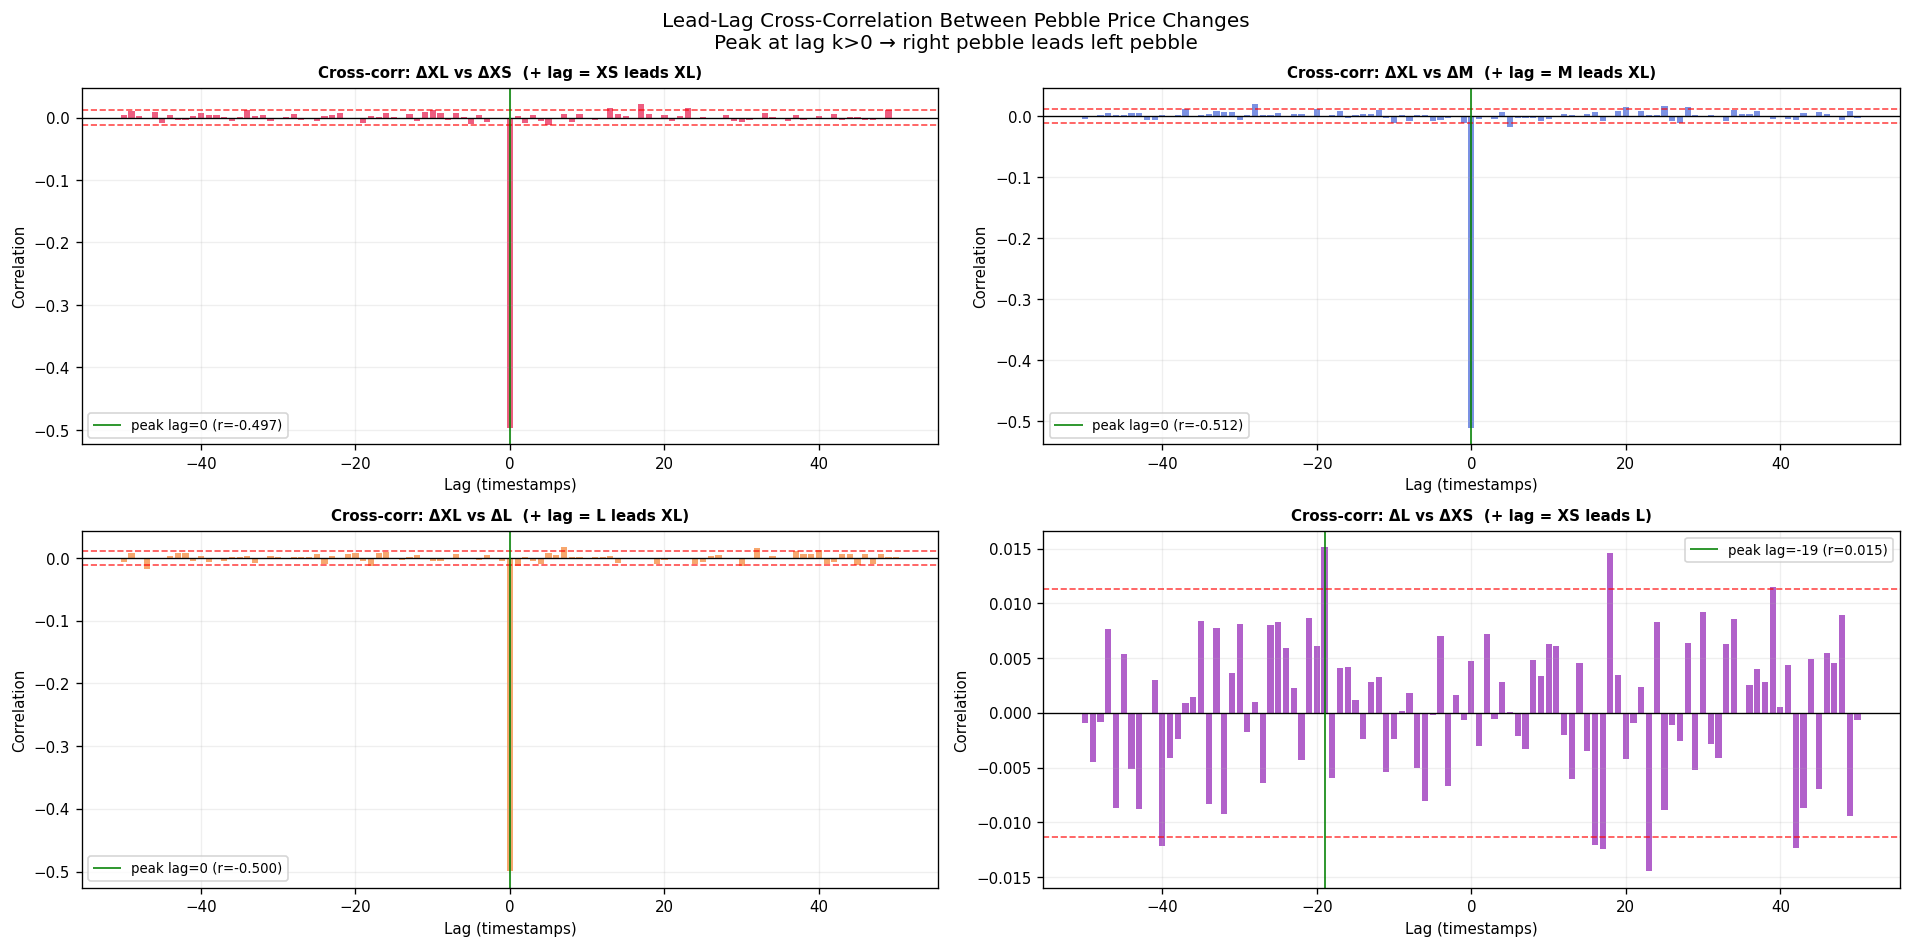

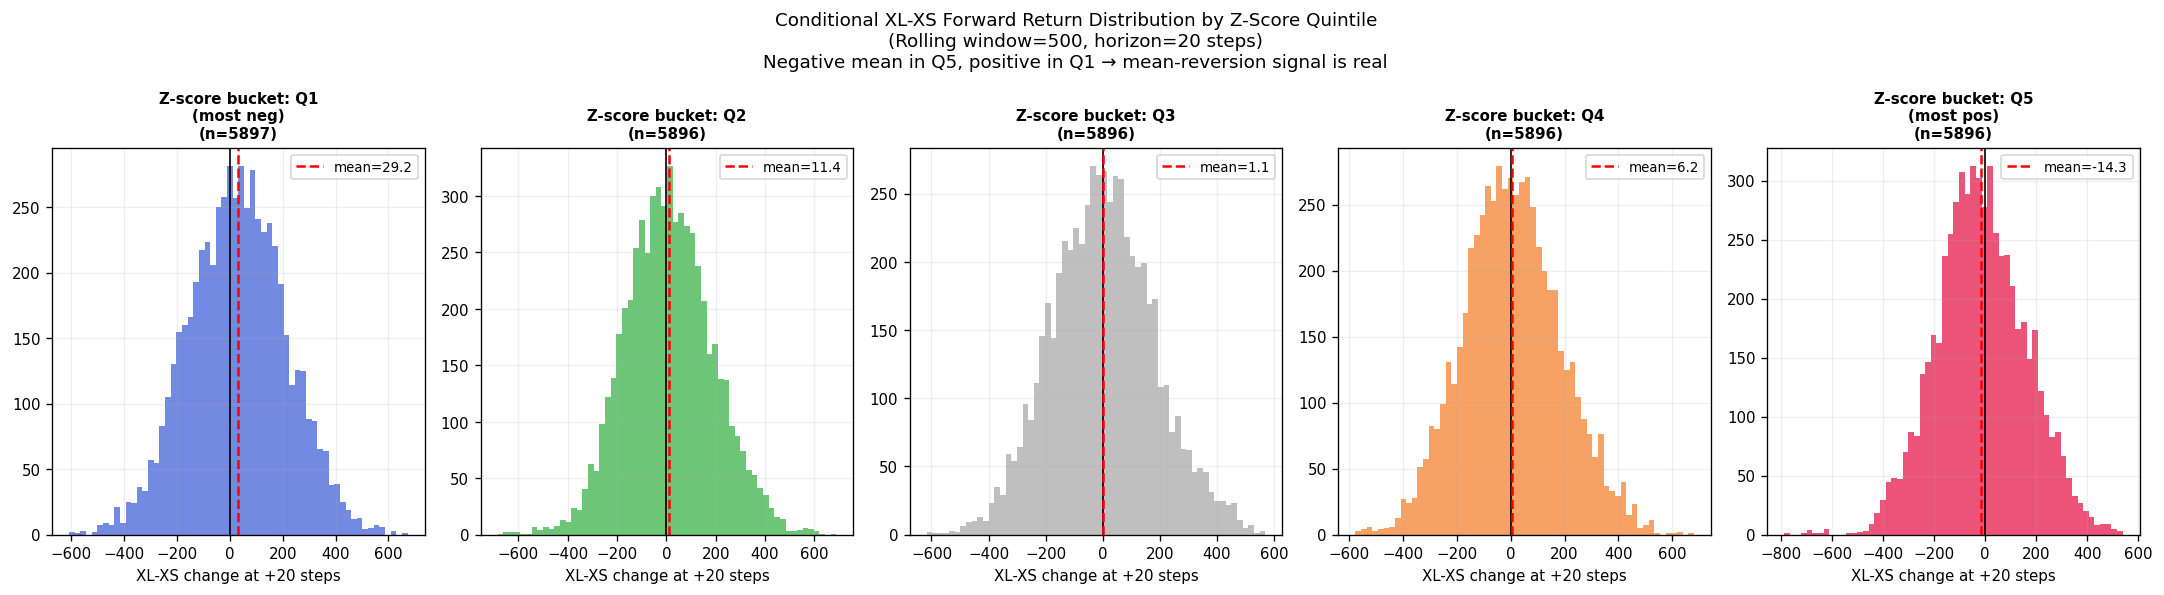

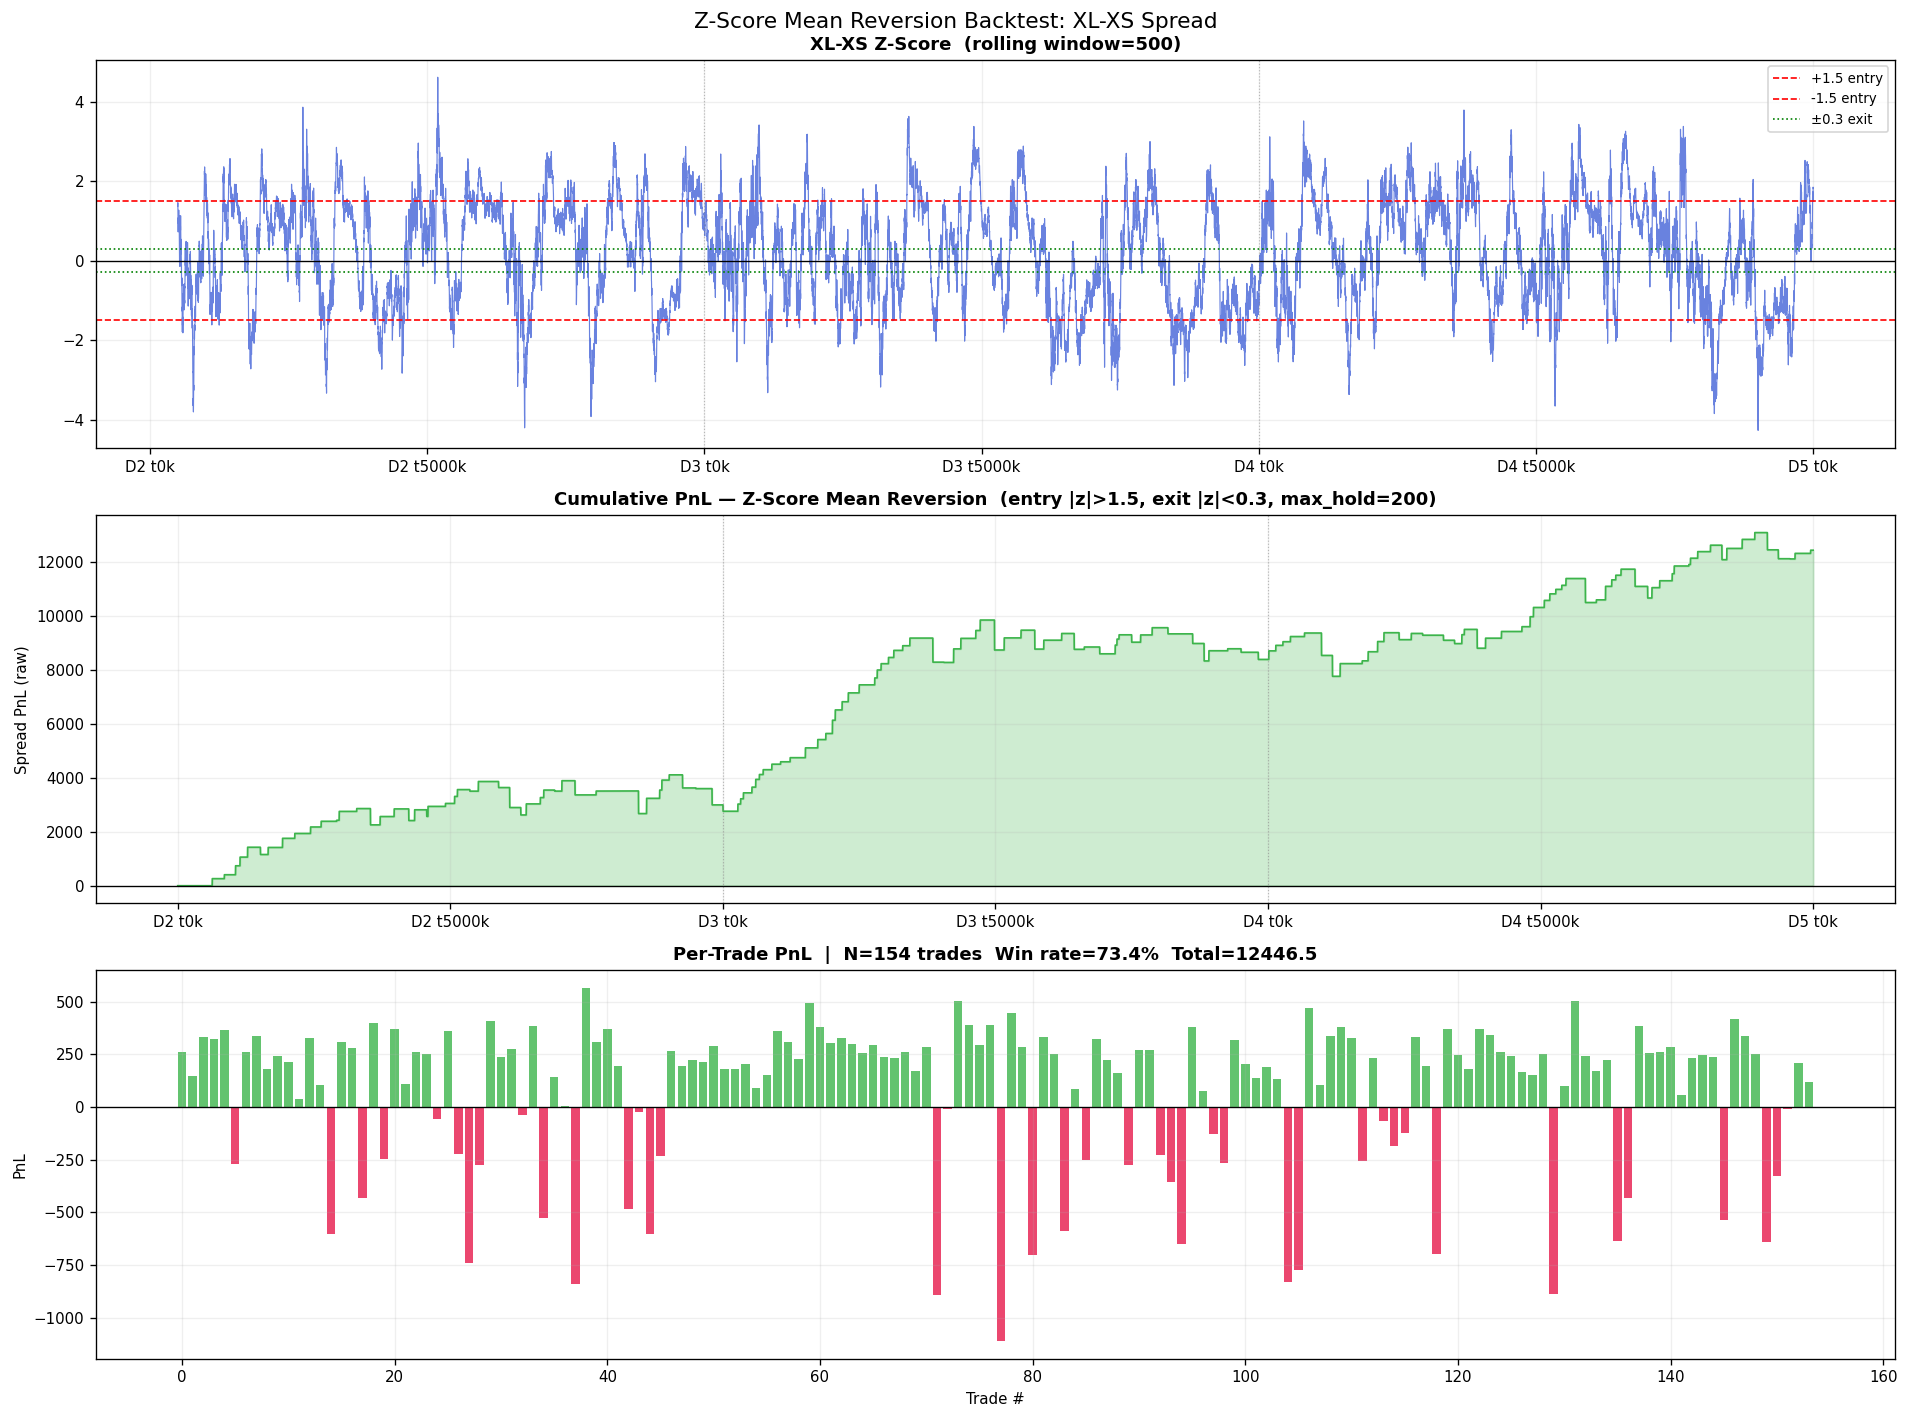


Backtest summary:
  Trades:     154
  Win rate:   73.4%
  Total PnL:  12446.50
  Avg PnL/trade: 80.82
  Sharpe proxy (PnL/std): 0.230


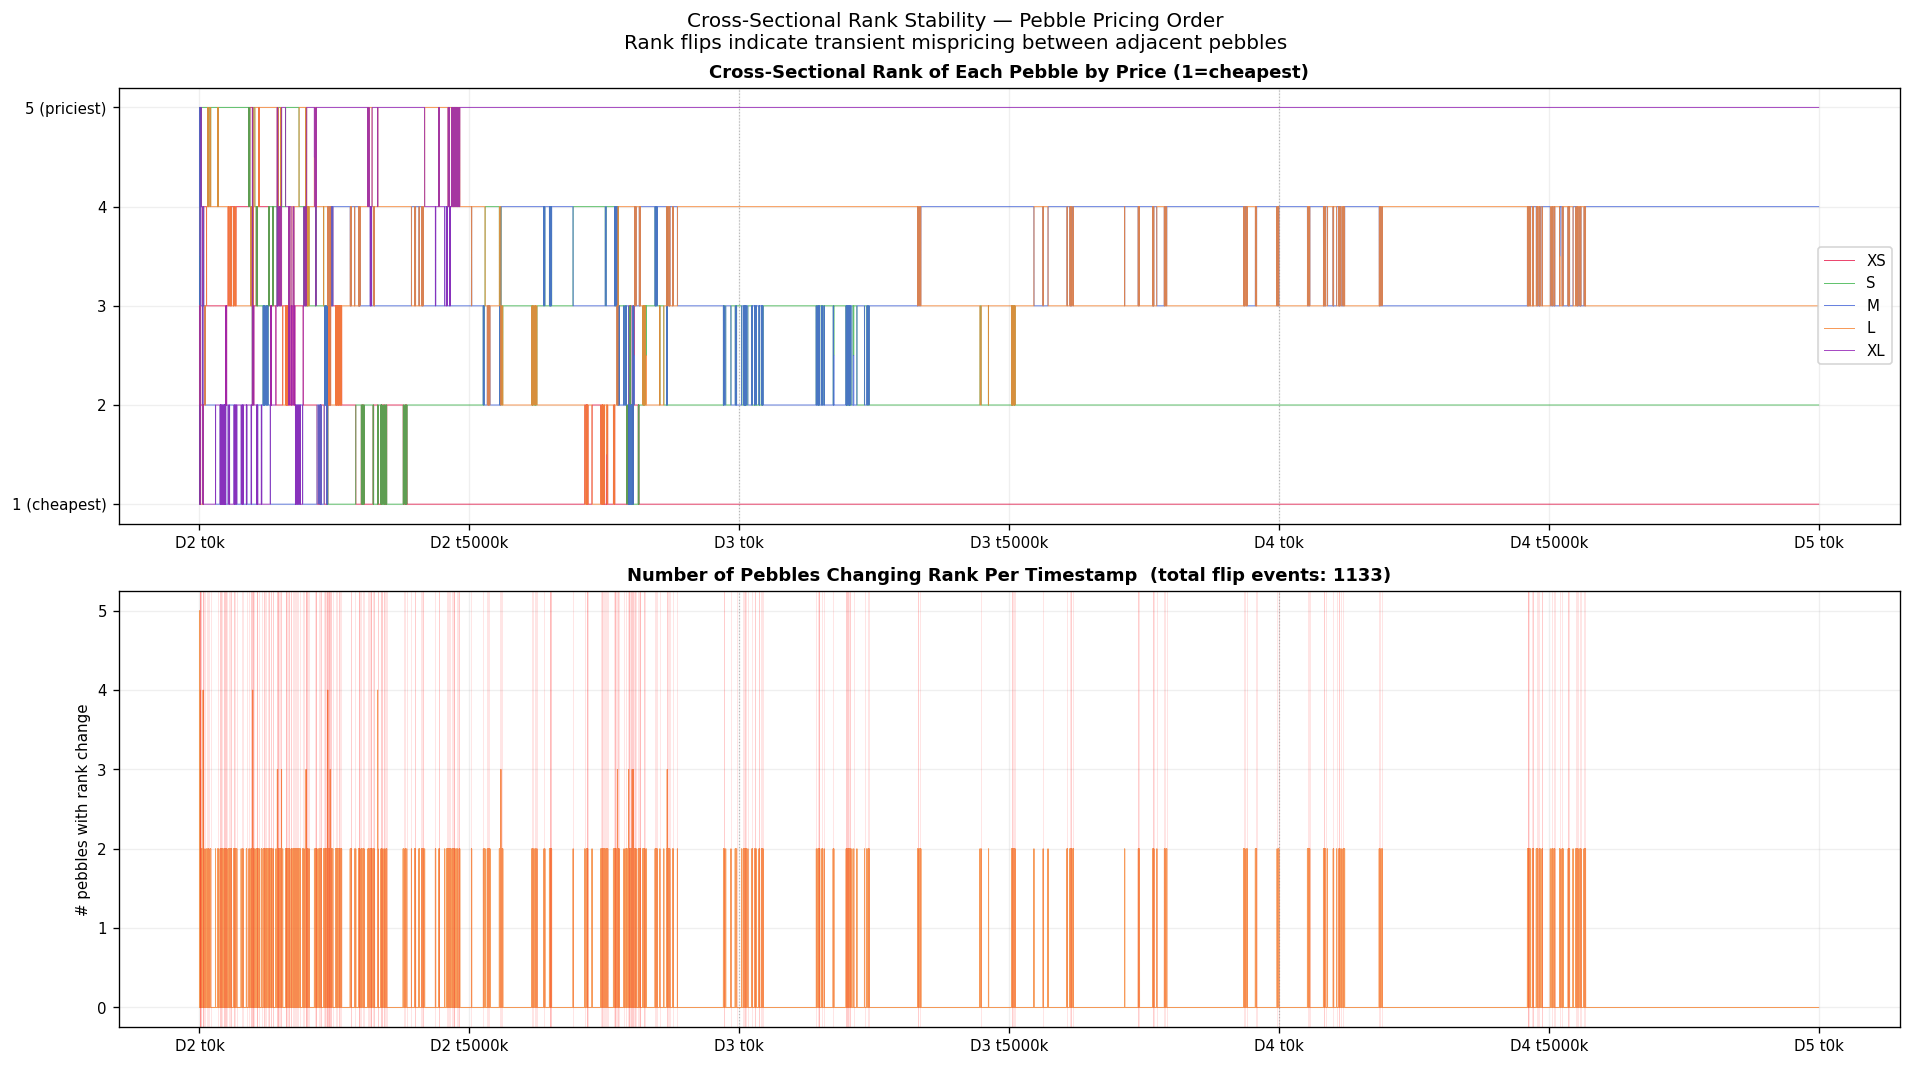


Rank transition frequency (% of steps each pebble stays at same rank):
  XS: 99.1% of steps at same rank
  S: 98.4% of steps at same rank
  M: 97.7% of steps at same rank
  L: 98.0% of steps at same rank
  XL: 99.1% of steps at same rank


In [8]:
# ─── CELL: Lead-lag, Conditional Distributions, Z-Score PnL, Rank Stability ───
from statsmodels.tsa.stattools import acf
import warnings
warnings.filterwarnings("ignore")

PRODUCTS = ['PEBBLES_XS', 'PEBBLES_S', 'PEBBLES_M', 'PEBBLES_L', 'PEBBLES_XL']
SHORT = {'PEBBLES_XS': 'XS', 'PEBBLES_S': 'S', 'PEBBLES_M': 'M',
         'PEBBLES_L': 'L', 'PEBBLES_XL': 'XL'}

peb = mid[PRODUCTS].dropna()
peb_idx = peb.index.values

XS = peb['PEBBLES_XS']
XL = peb['PEBBLES_XL']
xl_xs = XL - XS

# ── Helper: day-boundary vlines ──────────────────────────────────────────────
def day_vlines(ax):
    for ds in day_starts[1:]:
        ax.axvline(ds, color='gray', linestyle=':', linewidth=0.7, alpha=0.5)

fmt = mticker.FuncFormatter(
    lambda x, _: f"D{DAYS[0] + int(x // 1_000_000)} t{int(x % 1_000_000 // 100)}k")

# ══════════════════════════════════════════════════════════════════════════════
# PLOT 1 — Lead-lag cross-correlation: does XL lead XS (or vice versa)?
# Cross-correlate first-differences of XL and XS at lags ±50.
# A peak at lag k > 0 means XL moves first; k < 0 means XS moves first.
# ══════════════════════════════════════════════════════════════════════════════
MAX_LAG = 50
dXL = XL.diff().dropna()
dXS = XS.diff().dropna()
dM  = peb['PEBBLES_M'].diff().dropna()
dL  = peb['PEBBLES_L'].diff().dropna()
dS  = peb['PEBBLES_S'].diff().dropna()

def cross_corr(a, b, max_lag):
    """Normalized cross-correlation of series a vs b at lags -max_lag..+max_lag.
    Positive lag k: b leads a (a lags b by k steps)."""
    n = min(len(a), len(b))
    a, b = a.values[-n:], b.values[-n:]
    a = (a - a.mean()) / (a.std() + 1e-12)
    b = (b - b.mean()) / (b.std() + 1e-12)
    lags = range(-max_lag, max_lag + 1)
    cc   = [np.corrcoef(a[max_lag+k:n-max_lag+k], b[max_lag:n-max_lag])[0, 1]
            for k in lags]
    return list(lags), cc

pairs = [
    ('XL', 'XS', dXL, dXS, '#e6194b'),
    ('XL', 'M',  dXL, dM,  '#4363d8'),
    ('XL', 'L',  dXL, dL,  '#f58231'),
    ('L',  'XS', dL,  dXS, '#911eb4'),
]

fig, axes = plt.subplots(2, 2, figsize=(16, 8))
axes = axes.flatten()
conf = 1.96 / np.sqrt(len(dXL))

for ax, (a_name, b_name, da, db, col) in zip(axes, pairs):
    lags, cc = cross_corr(da, db, MAX_LAG)
    ax.bar(lags, cc, color=col, alpha=0.7, width=0.8)
    ax.axhline(0,     color='black', linewidth=0.8)
    ax.axhline( conf, color='red', linestyle='--', linewidth=1, alpha=0.7)
    ax.axhline(-conf, color='red', linestyle='--', linewidth=1, alpha=0.7)
    peak_lag  = lags[int(np.argmax(np.abs(cc)))]
    peak_val  = cc[int(np.argmax(np.abs(cc)))]
    ax.axvline(peak_lag, color='green', linestyle='-', linewidth=1.2, alpha=0.8,
               label=f'peak lag={peak_lag} (r={peak_val:.3f})')
    ax.set_title(f'Cross-corr: Δ{a_name} vs Δ{b_name}  (+ lag = {b_name} leads {a_name})',
                 fontweight='bold', fontsize=9)
    ax.set_xlabel('Lag (timestamps)')
    ax.set_ylabel('Correlation')
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.2)

plt.suptitle('Lead-Lag Cross-Correlation Between Pebble Price Changes\n'
             'Peak at lag k>0 → right pebble leads left pebble', fontsize=12)
plt.tight_layout()
plt.show()

# ══════════════════════════════════════════════════════════════════════════════
# PLOT 2 — Conditional return distribution: what happens after extreme z-scores?
# Bucket current XL-XS z-score into quintiles; plot forward return distribution
# of XL-XS at horizon H=20 for each bucket. If mean-reversion holds, extreme
# buckets should have sign-flipped forward returns.
# ══════════════════════════════════════════════════════════════════════════════
ROLL_W  = 500
HORIZON = 20

zscore  = (xl_xs - xl_xs.rolling(ROLL_W).mean()) / xl_xs.rolling(ROLL_W).std()
fwd_ret = xl_xs.shift(-HORIZON) - xl_xs   # future spread change

df_cond = pd.DataFrame({'z': zscore, 'fwd': fwd_ret}).dropna()
df_cond['bucket'] = pd.qcut(df_cond['z'], q=5,
                             labels=['Q1\n(most neg)', 'Q2', 'Q3', 'Q4', 'Q5\n(most pos)'])

bucket_colors = ['#4363d8', '#3cb44b', '#aaaaaa', '#f58231', '#e6194b']
fig, axes = plt.subplots(1, 5, figsize=(18, 5), sharey=False)

for ax, (bucket, col) in zip(axes, zip(df_cond['bucket'].cat.categories, bucket_colors)):
    sub  = df_cond[df_cond['bucket'] == bucket]['fwd']
    mean = sub.mean()
    ax.hist(sub, bins=60, color=col, alpha=0.75, edgecolor='none')
    ax.axvline(0,    color='black', linewidth=1)
    ax.axvline(mean, color='red',   linewidth=1.5, linestyle='--',
               label=f'mean={mean:.1f}')
    ax.set_title(f'Z-score bucket: {bucket}\n(n={len(sub)})',
                 fontweight='bold', fontsize=9)
    ax.set_xlabel(f'XL-XS change at +{HORIZON} steps')
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.2)

plt.suptitle(f'Conditional XL-XS Forward Return Distribution by Z-Score Quintile\n'
             f'(Rolling window={ROLL_W}, horizon={HORIZON} steps)\n'
             f'Negative mean in Q5, positive in Q1 → mean-reversion signal is real',
             fontsize=11)
plt.tight_layout()
plt.show()

# ══════════════════════════════════════════════════════════════════════════════
# PLOT 3 — Simulated z-score mean-reversion PnL on XL-XS spread
# Entry: |z| > Z_ENTRY → short spread if z>0, long if z<0
# Exit:  |z| < Z_EXIT  or position held > MAX_HOLD steps
# PnL tracked on a per-trade basis; cumulative PnL plotted across all days.
# ══════════════════════════════════════════════════════════════════════════════
Z_ENTRY  = 1.5
Z_EXIT   = 0.3
MAX_HOLD = 200

xl_xs_arr = xl_xs.values
z_arr     = zscore.values
n         = len(xl_xs_arr)

pnl_curve   = np.zeros(n)
trade_pnls  = []
position    = 0     # +1 long spread, -1 short spread, 0 flat
entry_price = 0.0
entry_step  = 0

for i in range(1, n):
    if np.isnan(z_arr[i]):
        continue
    if position == 0:
        if z_arr[i] > Z_ENTRY:
            position    = -1       # short spread (expect reversion down)
            entry_price = xl_xs_arr[i]
            entry_step  = i
        elif z_arr[i] < -Z_ENTRY:
            position    = +1       # long spread (expect reversion up)
            entry_price = xl_xs_arr[i]
            entry_step  = i
    else:
        exit_signal = (abs(z_arr[i]) < Z_EXIT) or ((i - entry_step) >= MAX_HOLD)
        if exit_signal:
            trade_pnl = position * (xl_xs_arr[i] - entry_price)
            trade_pnls.append(trade_pnl)
            pnl_curve[i:] += trade_pnl
            position = 0

fig, axes = plt.subplots(3, 1, figsize=(16, 12))

# 3a — Z-score with entry/exit bands
axes[0].plot(peb_idx, z_arr, color='#4363d8', linewidth=0.7, alpha=0.8)
axes[0].axhline( Z_ENTRY, color='red',   linestyle='--', linewidth=1, label=f'+{Z_ENTRY} entry')
axes[0].axhline(-Z_ENTRY, color='red',   linestyle='--', linewidth=1, label=f'-{Z_ENTRY} entry')
axes[0].axhline( Z_EXIT,  color='green', linestyle=':',  linewidth=1, label=f'±{Z_EXIT} exit')
axes[0].axhline(-Z_EXIT,  color='green', linestyle=':',  linewidth=1)
axes[0].axhline(0, color='black', linewidth=0.8)
day_vlines(axes[0])
axes[0].set_title(f'XL-XS Z-Score  (rolling window={ROLL_W})', fontweight='bold')
axes[0].legend(fontsize=8)
axes[0].grid(True, alpha=0.2)
axes[0].xaxis.set_major_formatter(fmt)

# 3b — Cumulative PnL
axes[1].plot(peb_idx, pnl_curve, color='#3cb44b', linewidth=1)
axes[1].fill_between(peb_idx, pnl_curve, 0, alpha=0.25, color='#3cb44b')
axes[1].axhline(0, color='black', linewidth=0.8)
day_vlines(axes[1])
axes[1].set_title(f'Cumulative PnL — Z-Score Mean Reversion  '
                  f'(entry |z|>{Z_ENTRY}, exit |z|<{Z_EXIT}, max_hold={MAX_HOLD})',
                  fontweight='bold')
axes[1].set_ylabel('Spread PnL (raw)')
axes[1].grid(True, alpha=0.2)
axes[1].xaxis.set_major_formatter(fmt)

# 3c — Per-trade PnL bar chart
trade_colors = ['#3cb44b' if p >= 0 else '#e6194b' for p in trade_pnls]
axes[2].bar(range(len(trade_pnls)), trade_pnls, color=trade_colors, alpha=0.8)
axes[2].axhline(0, color='black', linewidth=0.8)
win_rate = np.mean([p > 0 for p in trade_pnls]) if trade_pnls else 0
axes[2].set_title(f'Per-Trade PnL  |  N={len(trade_pnls)} trades  '
                  f'Win rate={win_rate:.1%}  Total={sum(trade_pnls):.1f}',
                  fontweight='bold')
axes[2].set_xlabel('Trade #')
axes[2].set_ylabel('PnL')
axes[2].grid(True, alpha=0.2)

plt.suptitle('Z-Score Mean Reversion Backtest: XL-XS Spread', fontsize=13)
plt.tight_layout()
plt.show()

print(f"\nBacktest summary:")
print(f"  Trades:     {len(trade_pnls)}")
print(f"  Win rate:   {win_rate:.1%}")
print(f"  Total PnL:  {sum(trade_pnls):.2f}")
print(f"  Avg PnL/trade: {np.mean(trade_pnls):.2f}" if trade_pnls else "  No trades fired.")
print(f"  Sharpe proxy (PnL/std): "
      f"{np.mean(trade_pnls)/np.std(trade_pnls):.3f}" if len(trade_pnls) > 1 else "")

# ══════════════════════════════════════════════════════════════════════════════
# PLOT 4 — Cross-sectional rank stability
# At each timestamp rank all 5 pebbles 1..5 by price. If the ordering is
# stable, it's a structural feature (e.g. XL always most expensive). If ranks
# flip frequently, those flip events might signal arbitrage opportunities.
# ══════════════════════════════════════════════════════════════════════════════
ranks = peb.rank(axis=1, ascending=True)   # 1=cheapest, 5=most expensive

# 4a — Rank of each pebble over time
fig, axes = plt.subplots(2, 1, figsize=(16, 9))
for prod, col in zip(PRODUCTS, COLORS5):
    axes[0].plot(peb_idx, ranks[prod].values, label=SHORT[prod],
                 color=col, linewidth=0.6, alpha=0.8)
day_vlines(axes[0])
axes[0].set_yticks([1, 2, 3, 4, 5])
axes[0].set_yticklabels(['1 (cheapest)', '2', '3', '4', '5 (priciest)'])
axes[0].set_title('Cross-Sectional Rank of Each Pebble by Price (1=cheapest)',
                  fontweight='bold')
axes[0].legend(fontsize=9)
axes[0].grid(True, alpha=0.2)
axes[0].xaxis.set_major_formatter(fmt)

# 4b — Rank-flip events: count how many pebbles changed rank vs previous step
rank_changes = (ranks.diff().abs() > 0).sum(axis=1)  # pebbles that moved rank
# A rank-flip requires at least 2 pebbles to change, so threshold at 2
flip_events  = (rank_changes >= 2).astype(int)
flip_ts      = peb_idx[flip_events.values == 1]

axes[1].plot(peb_idx, rank_changes.values, color='#f58231', linewidth=0.6, alpha=0.8)
for ft in flip_ts[::max(1, len(flip_ts)//300)]:   # subsample for readability
    axes[1].axvline(ft, color='red', linewidth=0.3, alpha=0.2)
day_vlines(axes[1])
axes[1].set_title(f'Number of Pebbles Changing Rank Per Timestamp  '
                  f'(total flip events: {flip_events.sum()})',
                  fontweight='bold')
axes[1].set_ylabel('# pebbles with rank change')
axes[1].grid(True, alpha=0.2)
axes[1].xaxis.set_major_formatter(fmt)

plt.suptitle('Cross-Sectional Rank Stability — Pebble Pricing Order\n'
             'Rank flips indicate transient mispricing between adjacent pebbles',
             fontsize=12)
plt.tight_layout()
plt.show()

# Rank transition matrix — how often does pebble i go from rank r to rank r±1?
print("\nRank transition frequency (% of steps each pebble stays at same rank):")
for prod in PRODUCTS:
    same = (ranks[prod].diff() == 0).mean()
    print(f"  {SHORT[prod]}: {same:.1%} of steps at same rank")

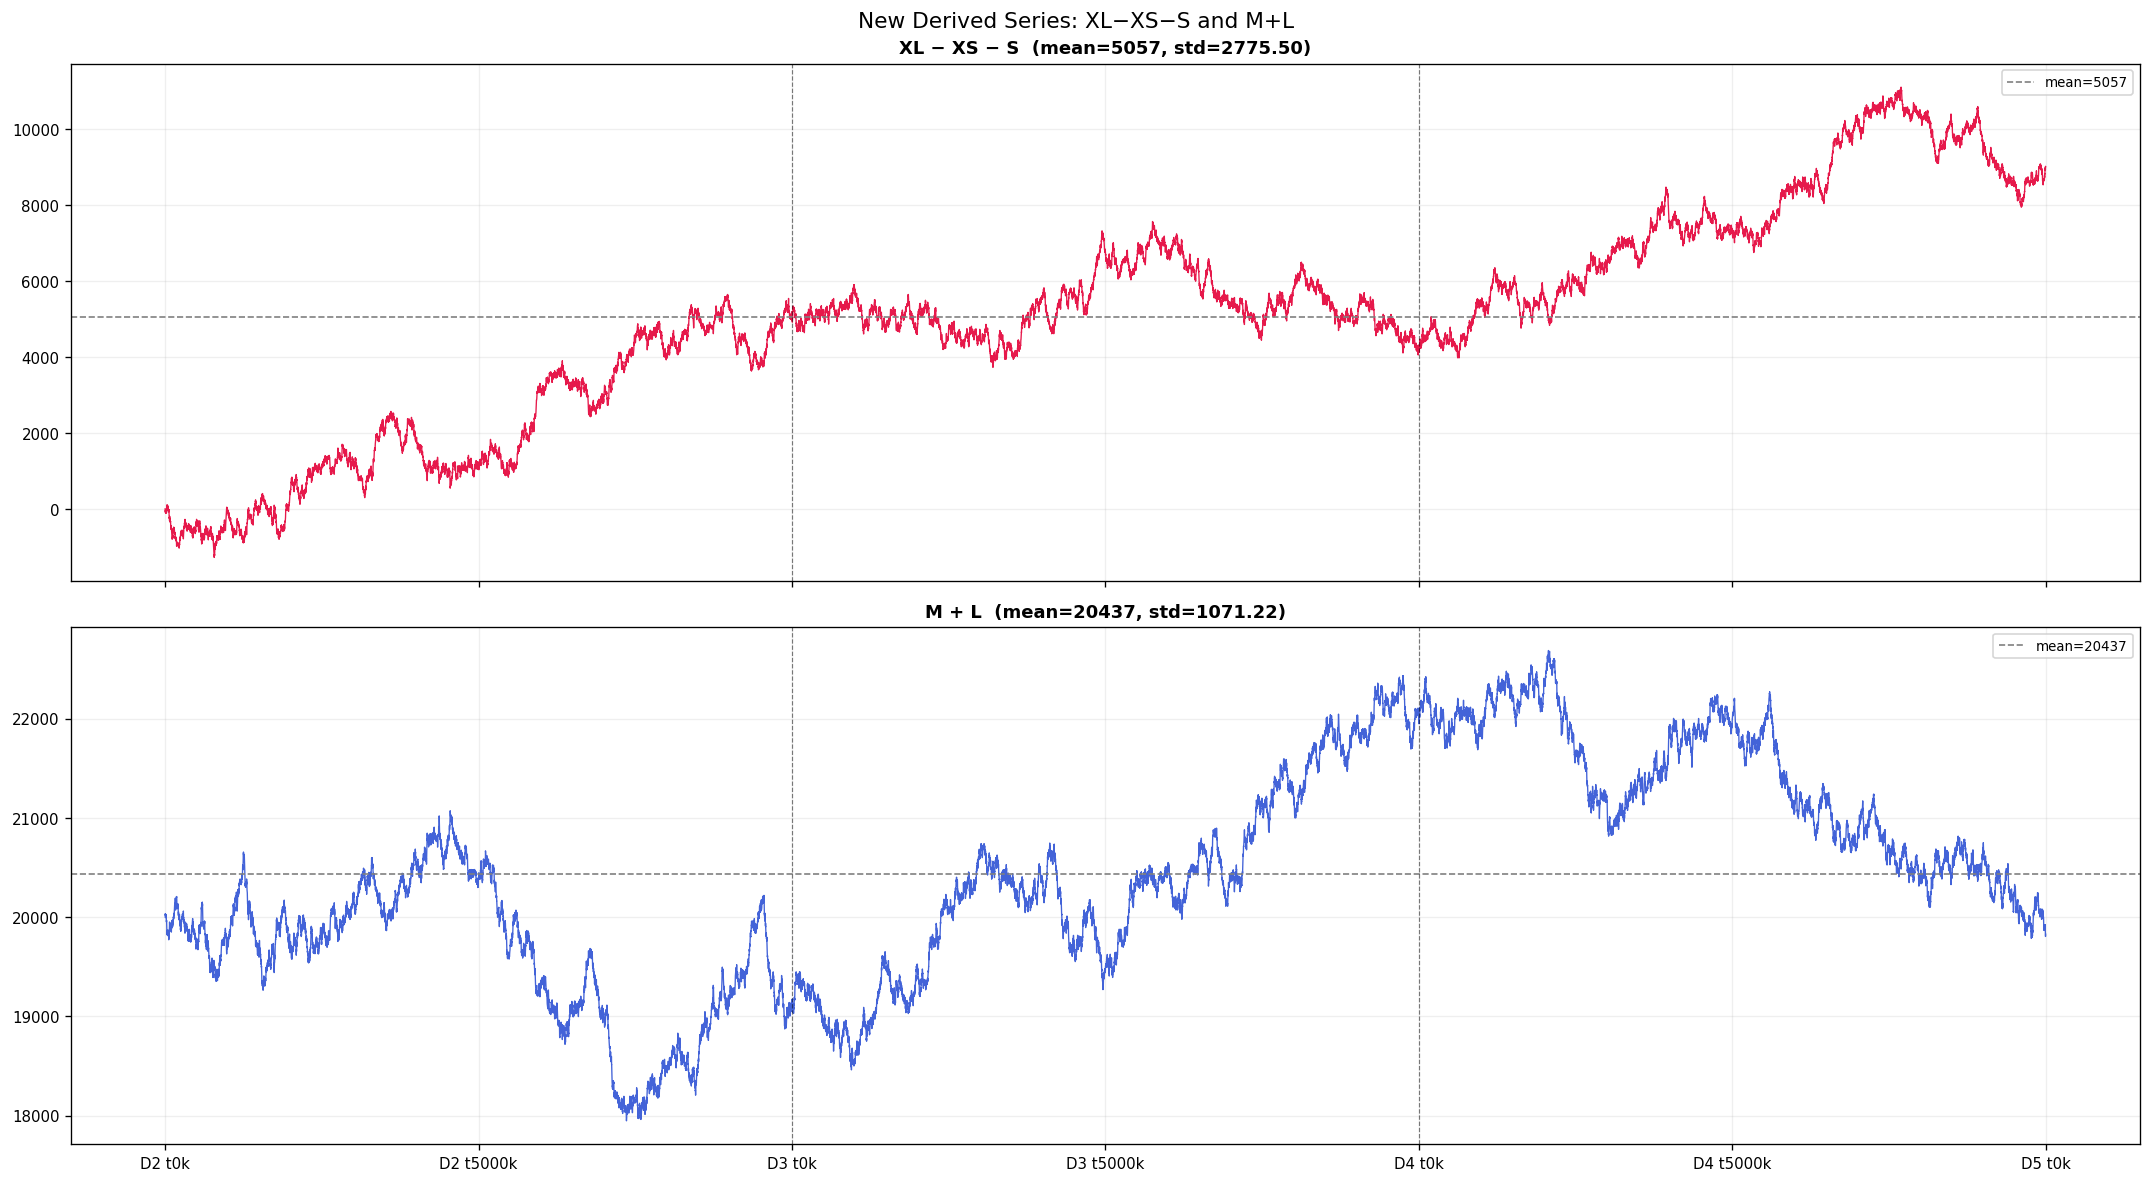

XL-XS-S  AC1=+0.0061
M+L      AC1=+0.0048

Correlation(XL-XS-S, M+L): 0.2990


In [9]:

# XL - XS - S  and  M + L
PRODUCTS5 = ['PEBBLES_XS', 'PEBBLES_S', 'PEBBLES_M', 'PEBBLES_L', 'PEBBLES_XL']
_peb = mid[PRODUCTS5].dropna()
_idx = _peb.index

_XS = _peb['PEBBLES_XS']
_S  = _peb['PEBBLES_S']
_M  = _peb['PEBBLES_M']
_L  = _peb['PEBBLES_L']
_XL = _peb['PEBBLES_XL']

s1 = _XL - 0.5*_XS - 0.5*_S
s2 = _M  + _L

fig, axes = plt.subplots(2, 1, figsize=(18, 10), sharex=True)

def _vl(ax):
    for ds in day_starts[1:]:
        ax.axvline(ds, color='black', linestyle='--', linewidth=0.7, alpha=0.5)

def _fm(ax):
    ax.xaxis.set_major_formatter(mticker.FuncFormatter(
        lambda x, _: f'D{DAYS[0] + int(x // 1_000_000)} t{int(x % 1_000_000 // 100)}k'))
    ax.grid(True, alpha=0.2)

axes[0].plot(_idx, s1.values, color='#e6194b', linewidth=0.8)
axes[0].axhline(s1.mean(), color='grey', linestyle='--', linewidth=1, label=f'mean={s1.mean():.0f}')
axes[0].set_title(f'XL − XS − S  (mean={s1.mean():.0f}, std={s1.std():.2f})', fontweight='bold')
axes[0].legend(fontsize=8)
_vl(axes[0]); _fm(axes[0])

axes[1].plot(_idx, s2.values, color='#4363d8', linewidth=0.8)
axes[1].axhline(s2.mean(), color='grey', linestyle='--', linewidth=1, label=f'mean={s2.mean():.0f}')
axes[1].set_title(f'M + L  (mean={s2.mean():.0f}, std={s2.std():.2f})', fontweight='bold')
axes[1].legend(fontsize=8)
_vl(axes[1]); _fm(axes[1])

plt.suptitle('New Derived Series: XL−XS−S and M+L', fontsize=13)
plt.tight_layout()
plt.show()

d1 = s1.diff().dropna()
d2 = s2.diff().dropna()
print(f'XL-XS-S  AC1={np.corrcoef(d1.values[:-1], d1.values[1:])[0,1]:+.4f}')
print(f'M+L      AC1={np.corrcoef(d2.values[:-1], d2.values[1:])[0,1]:+.4f}')
print(f'\nCorrelation(XL-XS-S, M+L): {s1.corr(s2):.4f}')


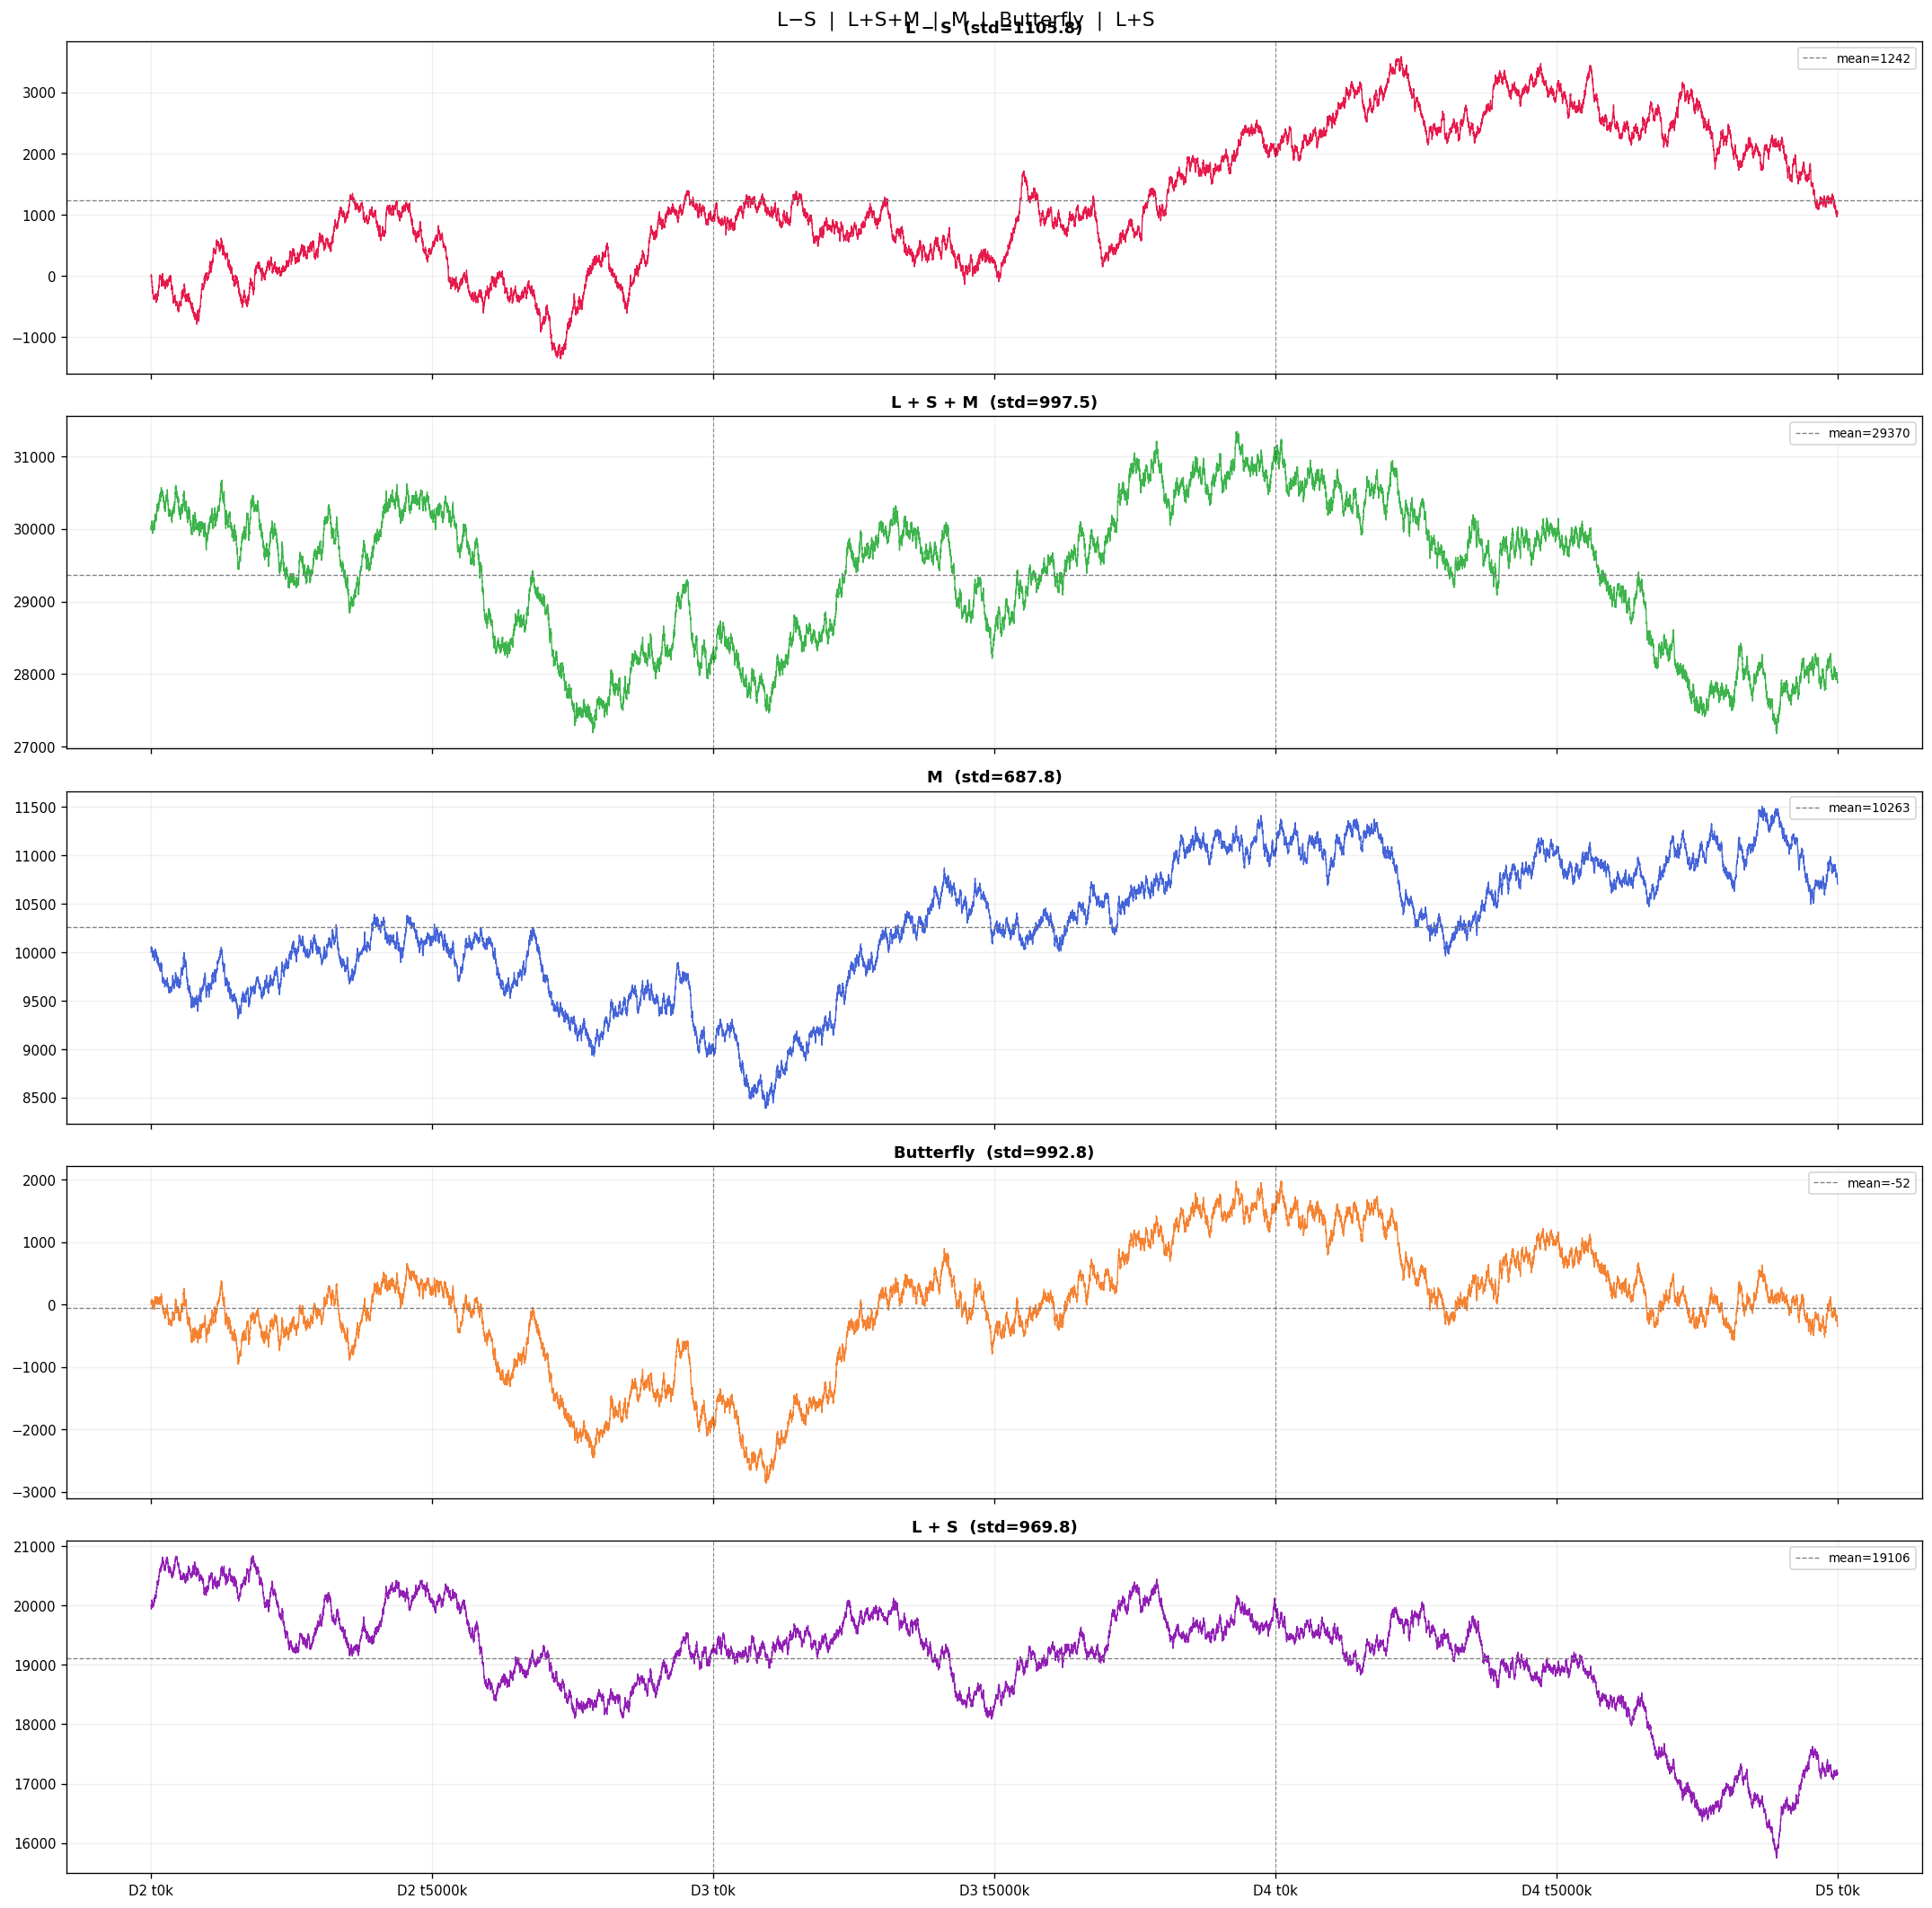

In [10]:

PRODUCTS5 = ['PEBBLES_XS', 'PEBBLES_S', 'PEBBLES_M', 'PEBBLES_L', 'PEBBLES_XL']
_peb = mid[PRODUCTS5].dropna()
_idx = _peb.index
_XS, _S, _M, _L, _XL = (_peb[f'PEBBLES_{x}'] for x in ['XS','S','M','L','XL'])

series = {
    'L − S':       (_L - _S,              '#e6194b'),
    'L + S + M':   (_L + _S + _M,         '#3cb44b'),
    'M':           (_M,                    '#4363d8'),
    'Butterfly':   (_M - (_XS + _XL) / 2, '#f58231'),
    'L + S':       (_L + _S,              '#911eb4'),
}

fig, axes = plt.subplots(len(series), 1, figsize=(18, 18), sharex=True)

for ax, (name, (s, col)) in zip(axes, series.items()):
    ax.plot(_idx, s.values, color=col, linewidth=0.8)
    ax.axhline(s.mean(), color='grey', linestyle='--', linewidth=0.8, label=f'mean={s.mean():.0f}')
    for ds in day_starts[1:]:
        ax.axvline(ds, color='black', linestyle='--', linewidth=0.7, alpha=0.4)
    ax.set_title(f'{name}  (std={s.std():.1f})', fontweight='bold')
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.2)
    ax.xaxis.set_major_formatter(mticker.FuncFormatter(
        lambda x, _: f'D{DAYS[0] + int(x // 1_000_000)} t{int(x % 1_000_000 // 100)}k'))

plt.suptitle('L−S  |  L+S+M  |  M  |  Butterfly  |  L+S', fontsize=13)
plt.tight_layout()
plt.show()


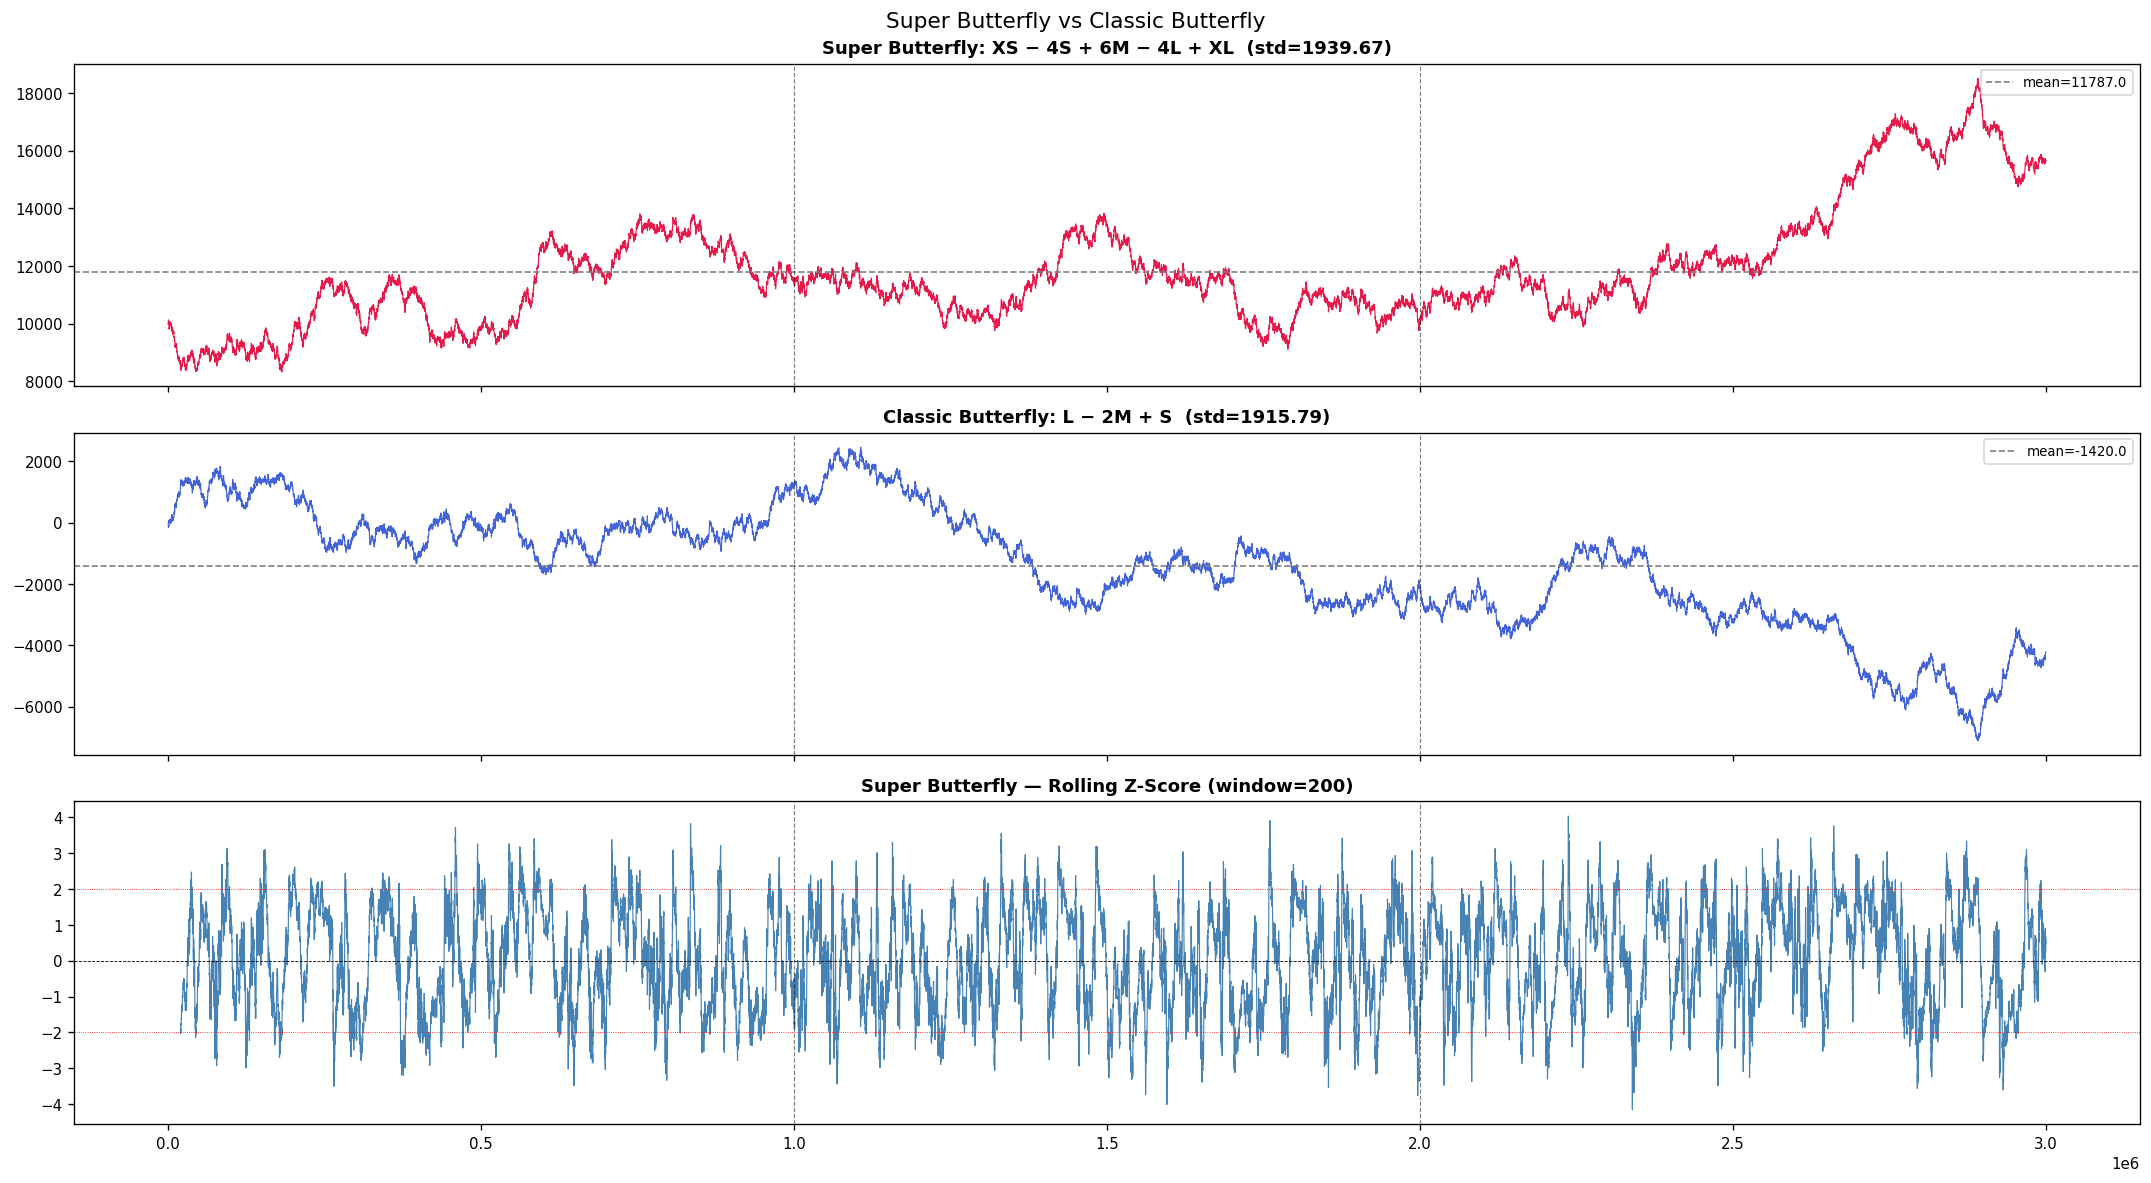

Super BF   mean=11787.00  std=1939.67  min=8329  max=18506
Classic BF mean=-1420.02  std=1915.79  min=-7114  max=2464
Correlation(super, classic): -0.7316


In [19]:

PRODUCTS5 = ['PEBBLES_XS', 'PEBBLES_S', 'PEBBLES_M', 'PEBBLES_L', 'PEBBLES_XL']
_peb = mid[PRODUCTS5].dropna()
_idx = _peb.index
_XS = _peb['PEBBLES_XS']
_S  = _peb['PEBBLES_S']
_M  = _peb['PEBBLES_M']
_L  = _peb['PEBBLES_L']
_XL = _peb['PEBBLES_XL']

# 4th-order finite difference: XS - 4S + 6M - 4L + XL
super_bf   = _XS - 1*_S + 1*_M - 1*_L + _XL
butterfly3 = _L - 2*_M + _S

roll_mean = super_bf.rolling(200).mean()
roll_std  = super_bf.rolling(200).std().clip(lower=0.1)
z_sbf     = (super_bf - roll_mean) / roll_std

fig, axes = plt.subplots(3, 1, figsize=(18, 10), sharex=True)

def _vl(ax):
    for ds in day_starts[1:]:
        ax.axvline(ds, color='black', linestyle='--', linewidth=0.7, alpha=0.5)

axes[0].plot(_idx, super_bf.values, lw=0.7, color='#e6194b')
axes[0].axhline(super_bf.mean(), color='grey', ls='--', lw=1, label=f'mean={super_bf.mean():.1f}')
axes[0].set_title(f'Super Butterfly: XS − 4S + 6M − 4L + XL  (std={super_bf.std():.2f})', fontweight='bold')
axes[0].legend(fontsize=8)
_vl(axes[0])

axes[1].plot(_idx, butterfly3.values, lw=0.7, color='#4363d8')
axes[1].axhline(butterfly3.mean(), color='grey', ls='--', lw=1, label=f'mean={butterfly3.mean():.1f}')
axes[1].set_title(f'Classic Butterfly: L − 2M + S  (std={butterfly3.std():.2f})', fontweight='bold')
axes[1].legend(fontsize=8)
_vl(axes[1])

axes[2].plot(_idx, z_sbf.values, lw=0.7, color='steelblue')
axes[2].axhline(0, color='k', lw=0.5, ls='--')
axes[2].axhline(2, color='r', lw=0.5, ls=':')
axes[2].axhline(-2, color='r', lw=0.5, ls=':')
axes[2].set_title('Super Butterfly — Rolling Z-Score (window=200)', fontweight='bold')
_vl(axes[2])

plt.suptitle('Super Butterfly vs Classic Butterfly', fontsize=13)
plt.tight_layout()
plt.show()

print(f'Super BF   mean={super_bf.mean():.2f}  std={super_bf.std():.2f}  min={super_bf.min():.0f}  max={super_bf.max():.0f}')
print(f'Classic BF mean={butterfly3.mean():.2f}  std={butterfly3.std():.2f}  min={butterfly3.min():.0f}  max={butterfly3.max():.0f}')
print(f'Correlation(super, classic): {super_bf.corr(butterfly3):.4f}')


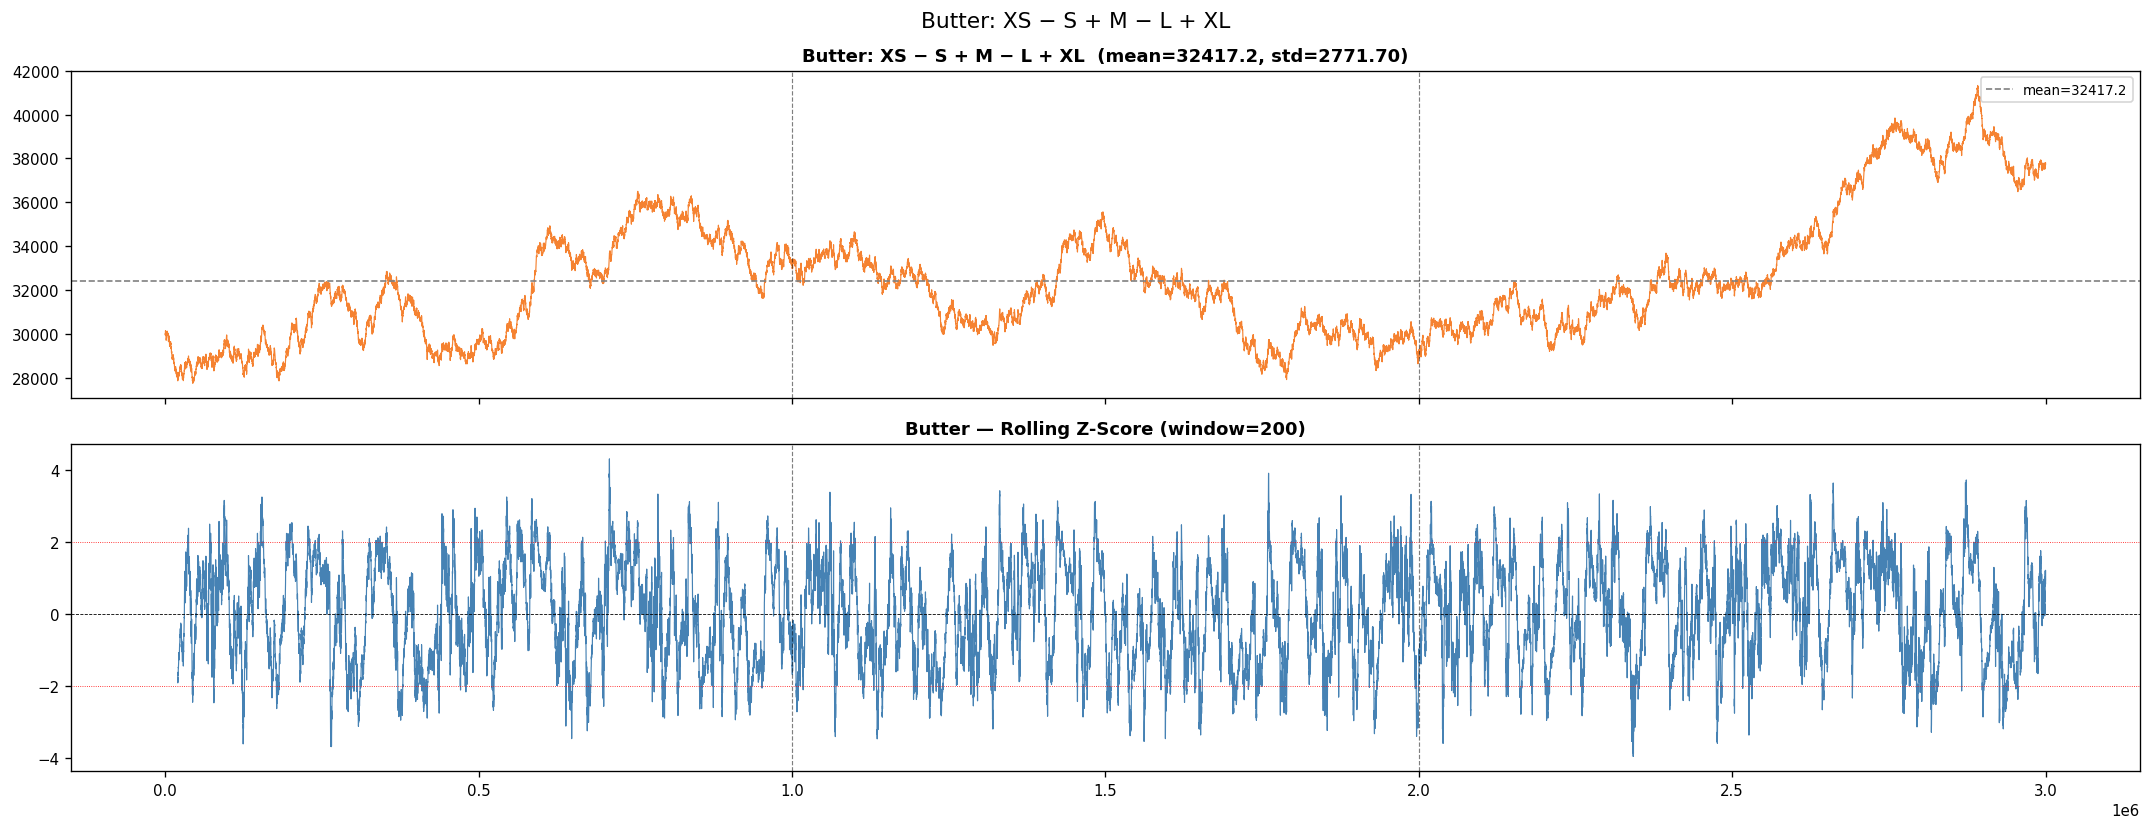

Butter  mean=32417.23  std=2771.70  min=27755  max=41329
Corr(butter, super_bf):  0.9718
Corr(butter, butterfly3): -0.5503


In [23]:

butter = 2*_XS - 1*_S + 1*_M - 1*_L + 2*_XL

roll_mean = butter.rolling(200).mean()
roll_std  = butter.rolling(200).std().clip(lower=0.1)
z_butter  = (butter - roll_mean) / roll_std

fig, axes = plt.subplots(2, 1, figsize=(18, 7), sharex=True)

axes[0].plot(_idx, butter.values, lw=0.7, color='#f58231')
axes[0].axhline(butter.mean(), color='grey', ls='--', lw=1, label=f'mean={butter.mean():.1f}')
axes[0].set_title(f'Butter: XS − S + M − L + XL  (mean={butter.mean():.1f}, std={butter.std():.2f})', fontweight='bold')
axes[0].legend(fontsize=8)
for ds in day_starts[1:]:
    axes[0].axvline(ds, color='black', ls='--', lw=0.7, alpha=0.5)

axes[1].plot(_idx, z_butter.values, lw=0.7, color='steelblue')
axes[1].axhline(0, color='k', lw=0.5, ls='--')
axes[1].axhline(2, color='r', lw=0.5, ls=':')
axes[1].axhline(-2, color='r', lw=0.5, ls=':')
axes[1].set_title('Butter — Rolling Z-Score (window=200)', fontweight='bold')
for ds in day_starts[1:]:
    axes[1].axvline(ds, color='black', ls='--', lw=0.7, alpha=0.5)

plt.suptitle('Butter: XS − S + M − L + XL', fontsize=13)
plt.tight_layout()
plt.show()

print(f'Butter  mean={butter.mean():.2f}  std={butter.std():.2f}  min={butter.min():.0f}  max={butter.max():.0f}')
print(f'Corr(butter, super_bf):  {butter.corr(super_bf):.4f}')
print(f'Corr(butter, butterfly3): {butter.corr(butterfly3):.4f}')


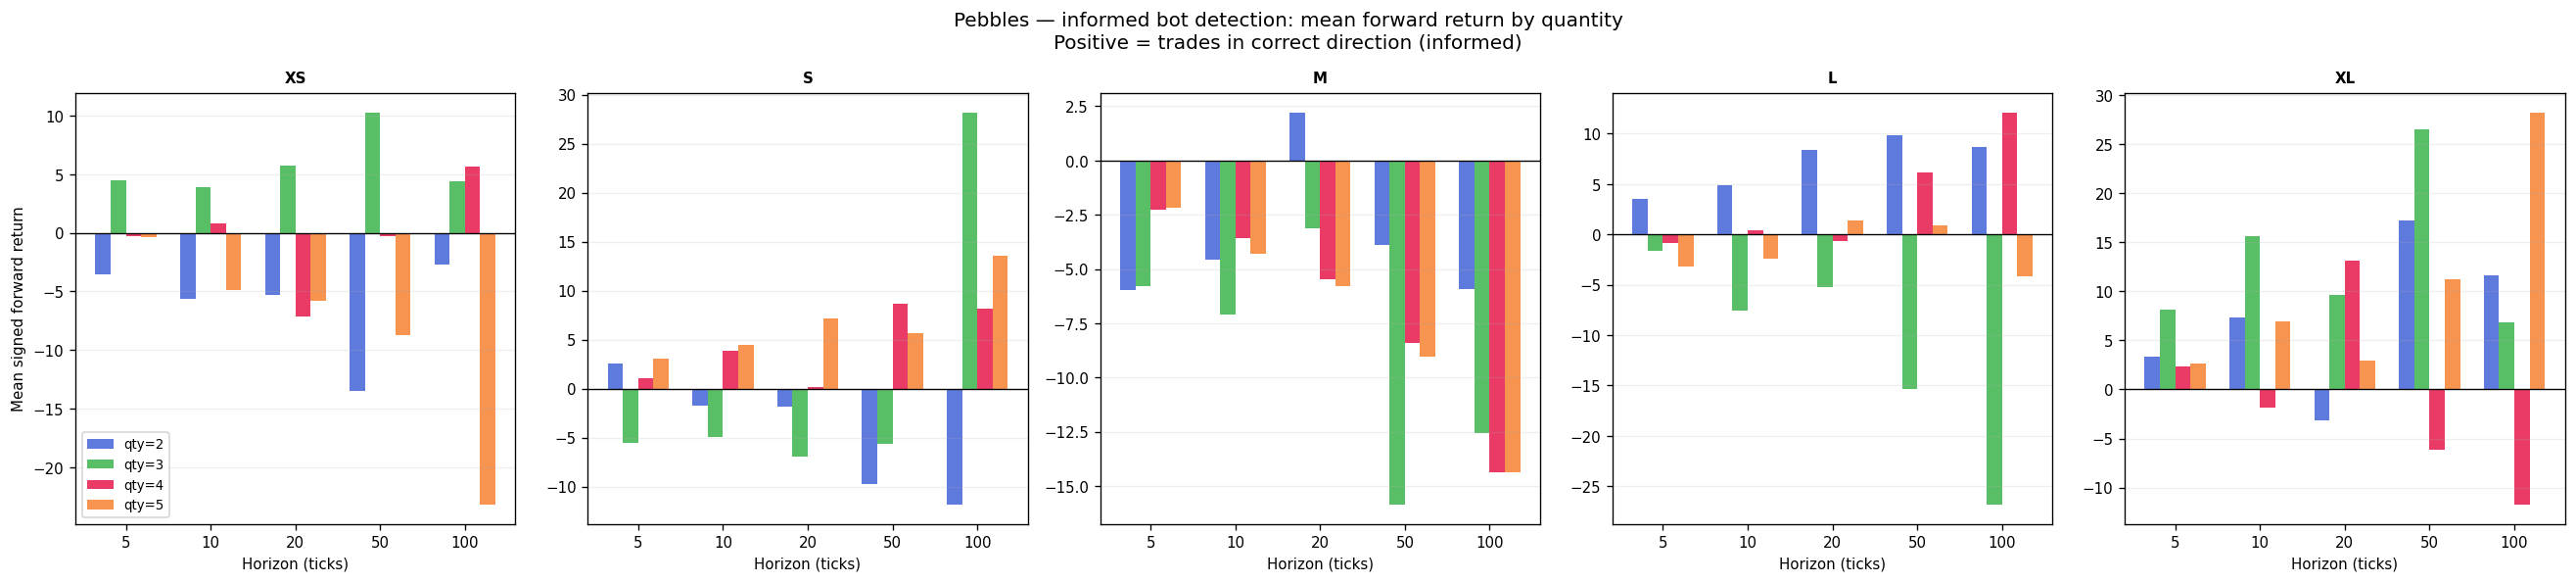

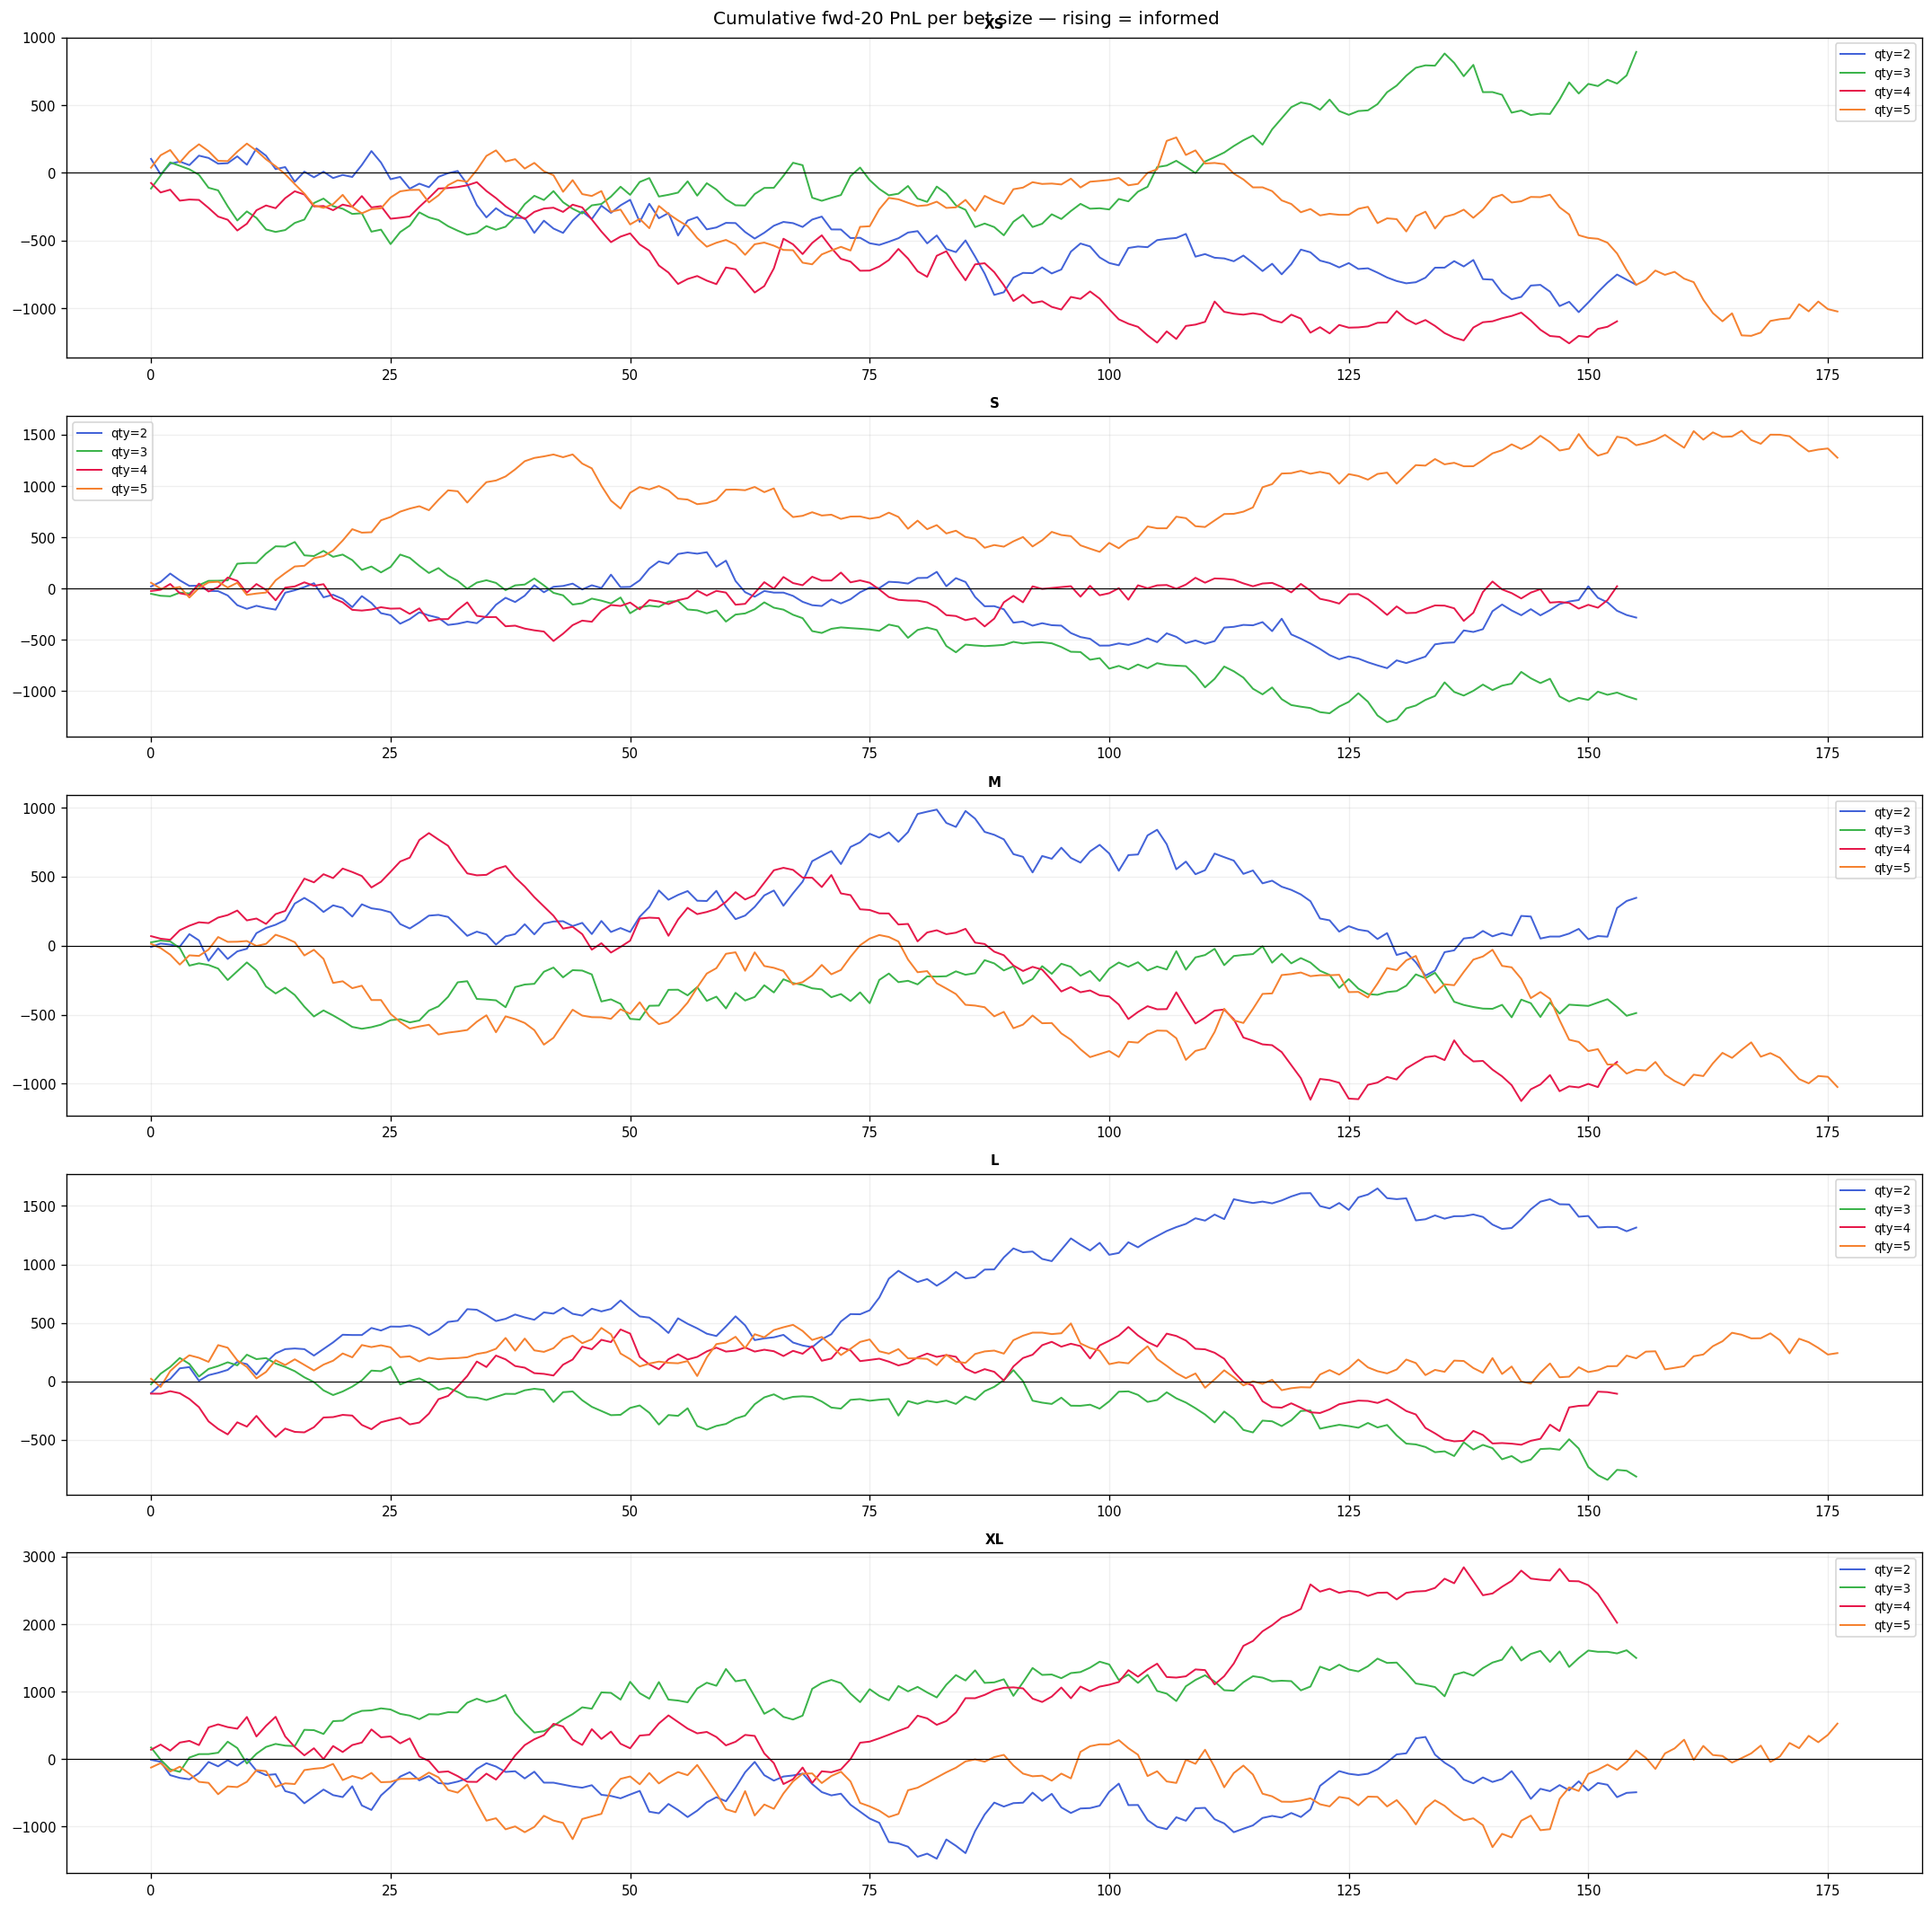

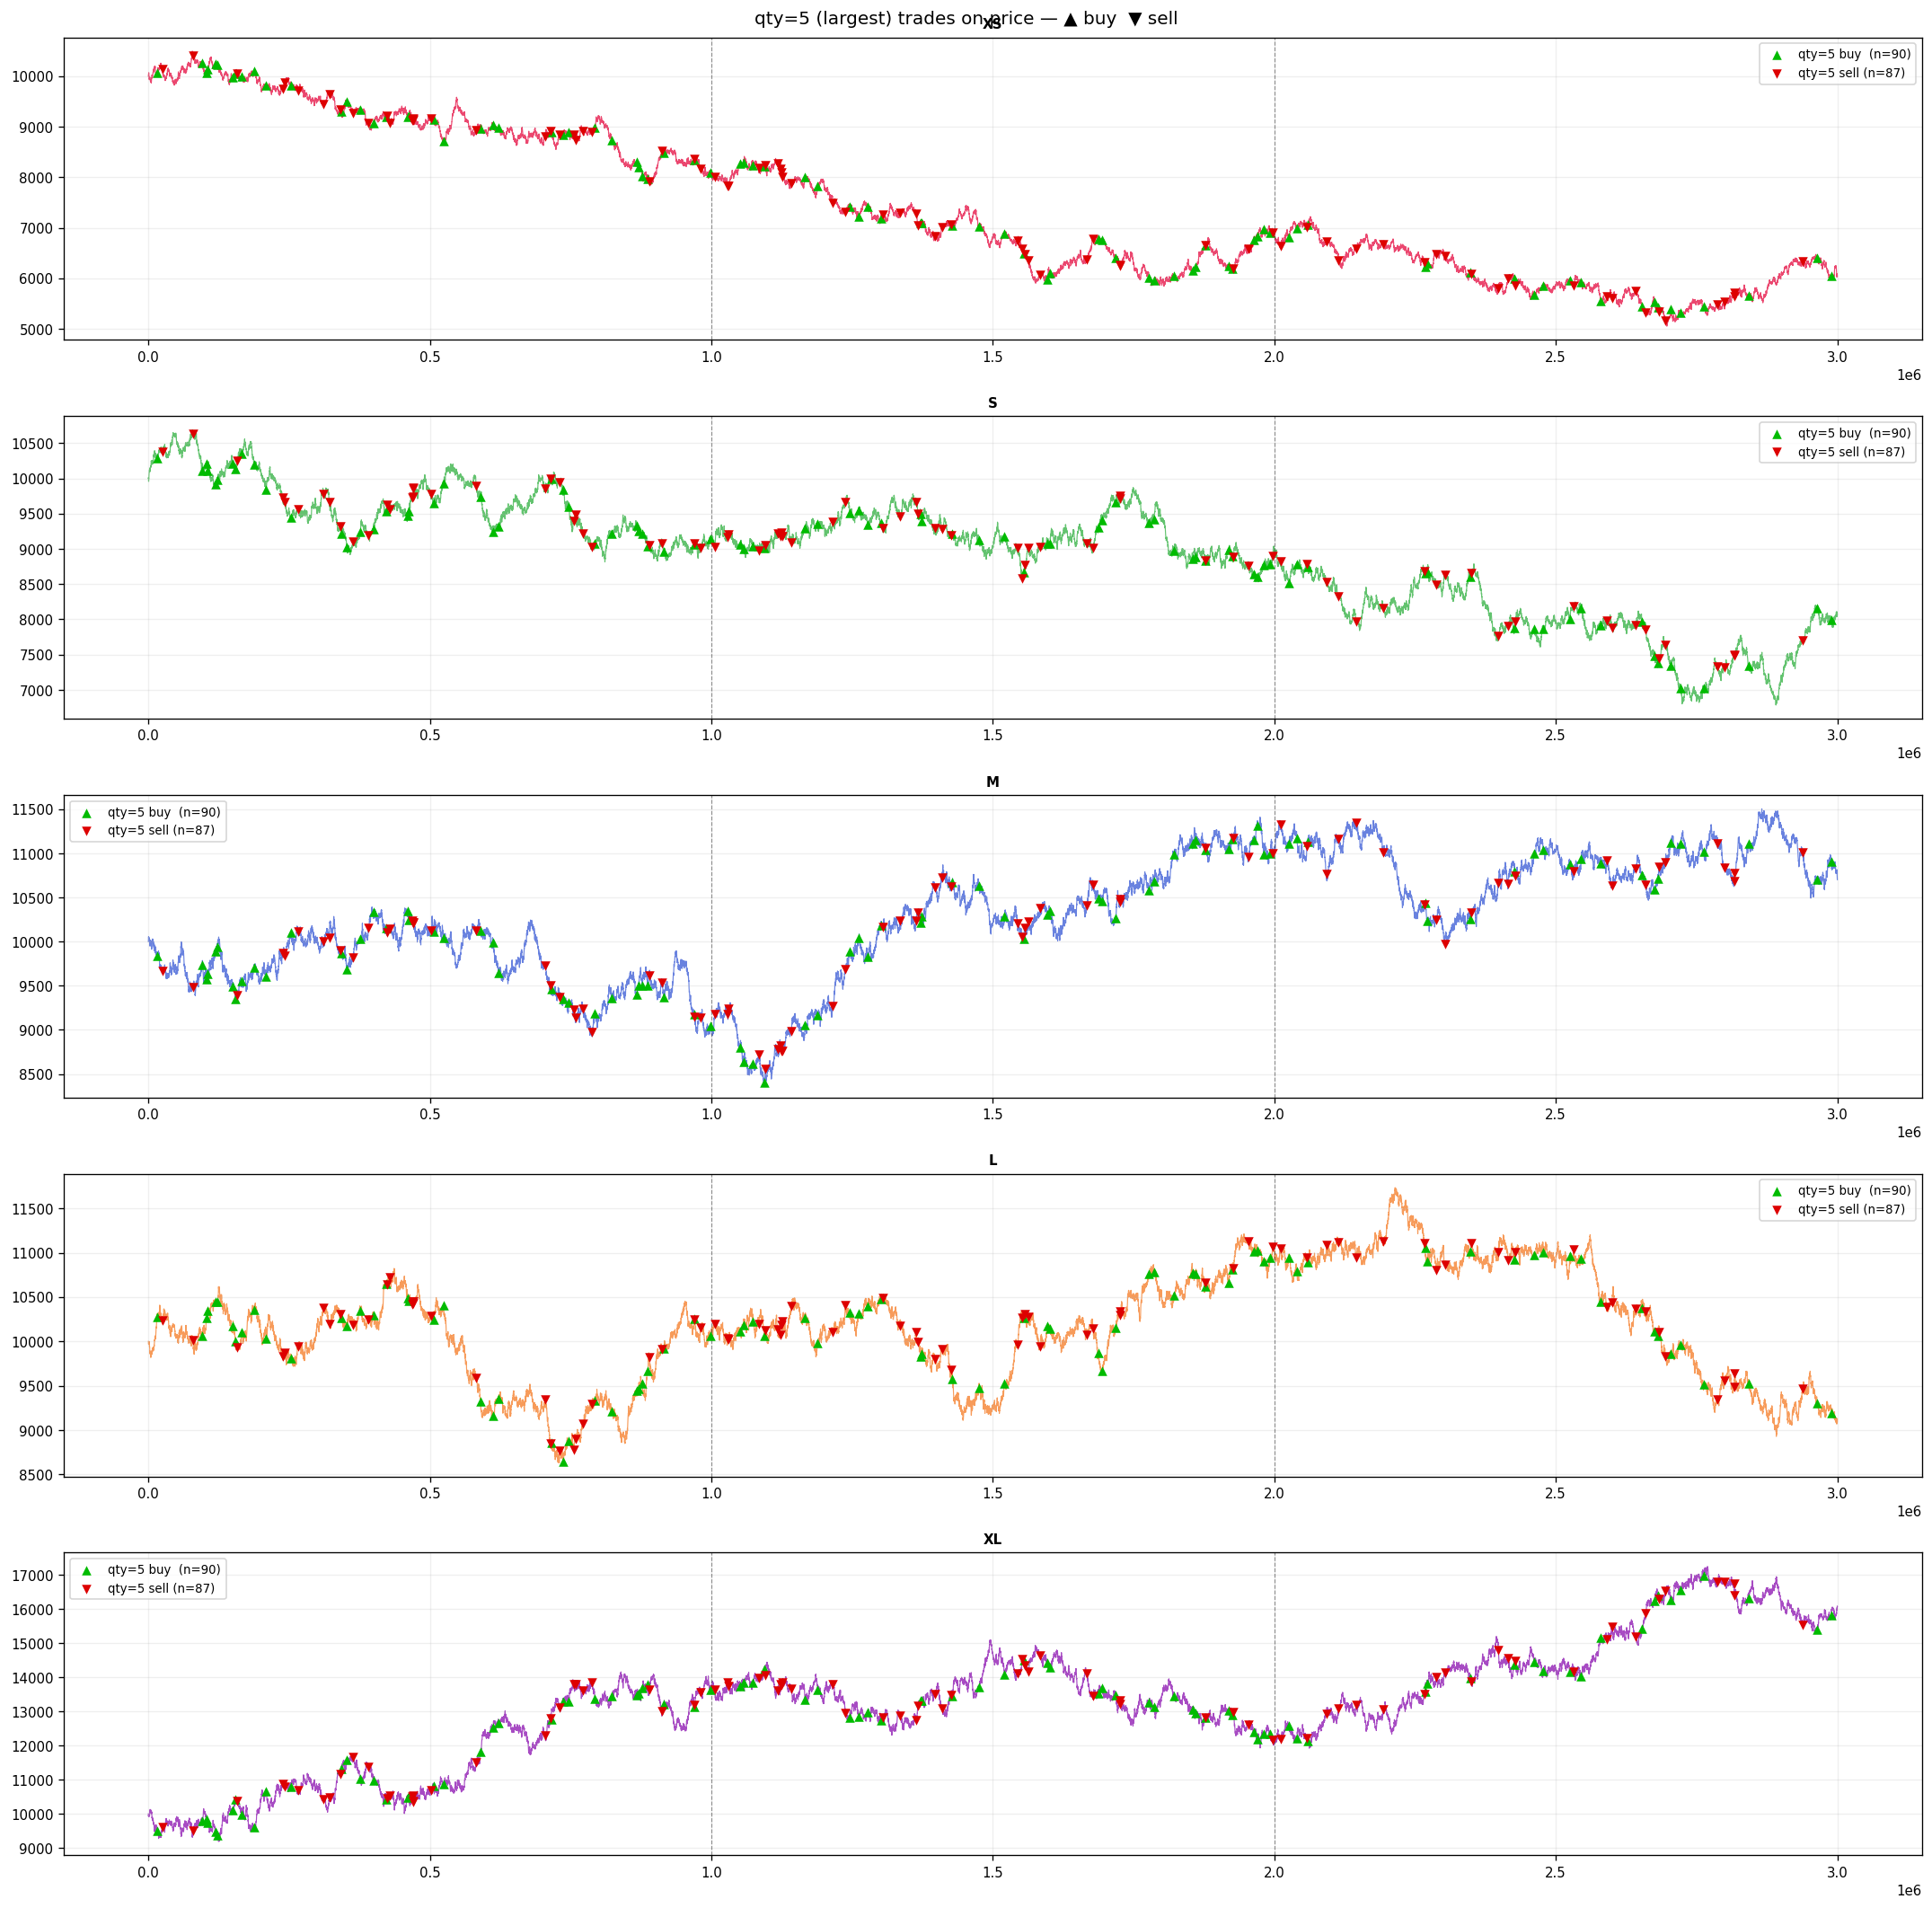


Product         qty=2 wr@h20  qty=3 wr@h20  qty=4 wr@h20  qty=5 wr@h20
----------------------------------------------------------------------
XS                    49.4%        55.1%        46.1%        49.2%
S                     48.1%        44.2%        48.1%        58.2%
M                     51.9%        48.7%        46.8%        47.5%
L                     56.4%        46.8%        45.5%        53.7%
XL                    48.7%        51.3%        57.1%        52.5%


In [24]:
# ── Pebbles: informed bot analysis ───────────────────────────────────────────
# All trades are XIRECS. Quantities: 2, 3, 4, 5.
# Direction inferred from price vs mid at trade timestamp.
# ─────────────────────────────────────────────────────────────────────────────
import numpy as np

PEB_PRODUCTS = ['PEBBLES_XS', 'PEBBLES_S', 'PEBBLES_M', 'PEBBLES_L', 'PEBBLES_XL']
PEB_COLORS   = ['#e6194b', '#3cb44b', '#4363d8', '#f58231', '#911eb4']
HORIZONS     = [5, 10, 20, 50, 100]
QTYS         = [2, 3, 4, 5]
Q_COLORS     = {2: '#4363d8', 3: '#3cb44b', 4: '#e6194b', 5: '#f58231'}

_tframes = []
for d in DAYS:
    tf = pd.read_csv(BASE / f'trades_round_5_day_{d}.csv', sep=';')
    tf['day'] = d
    _tframes.append(tf)
_trades_all = pd.concat(_tframes, ignore_index=True)
_trades_all['global_ts'] = (_trades_all['day'] - DAYS[0]) * 1_000_000 + _trades_all['timestamp']
_peb_trades = _trades_all[_trades_all['symbol'].isin(PEB_PRODUCTS)].copy()

def build_peb_trades(prod):
    t = _peb_trades[_peb_trades['symbol'] == prod].copy()
    m = mid[prod].dropna()
    t = t.merge(m.rename('mid'), left_on='global_ts', right_index=True, how='left')
    # infer direction: trade below mid = bot bought, above mid = bot sold
    t['direction'] = (t['price'] - t['mid']).apply(lambda x: -1 if x > 0 else 1)
    mid_arr = m.values
    mid_idx = m.index.values
    for h in HORIZONS:
        fwd = []
        for ts, dr in zip(t['global_ts'], t['direction']):
            pos = np.searchsorted(mid_idx, ts)
            fwd.append(dr * (mid_arr[pos+h] - mid_arr[pos]) if pos + h < len(mid_arr) else np.nan)
        t[f'fwd_{h}'] = fwd
    return t

peb_trade_tables = {prod: build_peb_trades(prod) for prod in PEB_PRODUCTS}

# ── PLOT 1: Mean forward return by quantity at each horizon ──────────────────
fig, axes = plt.subplots(1, 5, figsize=(22, 5), sharey=False)
x = np.arange(len(HORIZONS))
w = 0.18

for ax, prod in zip(axes, PEB_PRODUCTS):
    t = peb_trade_tables[prod]
    for i, (q, col) in enumerate(Q_COLORS.items()):
        means = [t[t['quantity'] == q][f'fwd_{h}'].mean() for h in HORIZONS]
        ax.bar(x + i * w, means, width=w, color=col, alpha=0.85, label=f'qty={q}')
    ax.axhline(0, color='black', linewidth=0.8)
    ax.set_xticks(x + 1.5 * w)
    ax.set_xticklabels([str(h) for h in HORIZONS])
    ax.set_xlabel('Horizon (ticks)')
    ax.set_title(prod.replace('PEBBLES_', ''), fontweight='bold', fontsize=9)
    ax.grid(True, alpha=0.2, axis='y')

axes[0].set_ylabel('Mean signed forward return')
axes[0].legend(fontsize=8)
fig.suptitle('Pebbles — informed bot detection: mean forward return by quantity\n'
             'Positive = trades in correct direction (informed)', fontsize=12)
plt.tight_layout()
plt.show()

# ── PLOT 2: Cumulative PnL following each quantity ────────────────────────────
HORIZON = 20
fig, axes = plt.subplots(5, 1, figsize=(18, 18), sharex=False)

for ax, prod, col in zip(axes, PEB_PRODUCTS, PEB_COLORS):
    t = peb_trade_tables[prod]
    for q, qcol in Q_COLORS.items():
        sub = t[t['quantity'] == q][f'fwd_{HORIZON}'].dropna()
        ax.plot(range(len(sub)), sub.cumsum().values, color=qcol, lw=1.2, label=f'qty={q}')
    ax.axhline(0, color='black', lw=0.7)
    ax.set_title(prod.replace('PEBBLES_', ''), fontweight='bold', fontsize=9)
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.2)

fig.suptitle(f'Cumulative fwd-{HORIZON} PnL per bet size — rising = informed', fontsize=12)
plt.tight_layout()
plt.show()

# ── PLOT 3: Price with qty=5 (largest) buy/sell markers ──────────────────────
fig, axes = plt.subplots(5, 1, figsize=(18, 18), sharex=False)

for ax, prod, col in zip(axes, PEB_PRODUCTS, PEB_COLORS):
    s   = mid[prod].dropna()
    t5  = peb_trade_tables[prod][peb_trade_tables[prod]['quantity'] == 5]
    buys  = t5[t5['direction'] ==  1]
    sells = t5[t5['direction'] == -1]
    ax.plot(s.index, s.values, color=col, lw=0.7, alpha=0.8, zorder=1)
    ax.scatter(buys['global_ts'],  buys['price'],  s=40, marker='^',
               color='#00bb00', zorder=3, label=f'qty=5 buy  (n={len(buys)})',  linewidths=0)
    ax.scatter(sells['global_ts'], sells['price'], s=40, marker='v',
               color='#dd0000', zorder=3, label=f'qty=5 sell (n={len(sells)})', linewidths=0)
    for ds in day_starts[1:]:
        ax.axvline(ds, color='black', ls='--', lw=0.7, alpha=0.4)
    ax.set_title(prod.replace('PEBBLES_', ''), fontweight='bold', fontsize=9)
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.2)

fig.suptitle('qty=5 (largest) trades on price — ▲ buy  ▼ sell', fontsize=12)
plt.tight_layout()
plt.show()

# ── Win rate table ────────────────────────────────────────────────────────────
print(f'\n{"Product":<14}', end='')
for q in QTYS:
    print(f'  qty={q} wr@h20', end='')
print()
print('-' * 70)
for prod in PEB_PRODUCTS:
    t = peb_trade_tables[prod]
    print(f'{prod.replace("PEBBLES_",""):<14}', end='')
    for q in QTYS:
        sub = t[t['quantity'] == q]['fwd_20'].dropna()
        wr  = (sub > 0).mean() * 100 if len(sub) > 0 else float('nan')
        print(f'  {wr:>10.1f}%', end='')
    print()
